# Metamorphic testing of data imputers — mutation analysis on real library code

This notebook runs the full experiment. **The subjects are the real scikit-learn classes** (`SimpleImputer`, `KNNImputer` with its nan-Euclidean distance kernel, `IterativeImputer`), and the **mutants are generated automatically from their source code** by an AST mutation engine. The study's own SoftImpute solver is included as a clearly labelled, secondary subject.

Design summary:

* **Mutants** are enumerated from the real source with a 17-category operator catalogue (arithmetic, relational, boundary, logical, branch, constant, tolerance, semantic, reduction, NaN, dtype, tie, axis, copy, validation, kwarg, statement). Equivalent candidates, crash-everywhere mutants and un-covered mutants are separated *before* scoring.
* **Reference gate.** The unmutated libraries are also tested: a property can only kill a mutant in the conditions in which the unmutated implementation satisfies it, and any property that real scikit-learn violates is reported as a natural behaviour finding.
* **Conditions** are heterogeneous and randomised (Latin-hypercube sampling of missing rate, rows and columns; real and synthetic data sources; MCAR, MAR and MNAR; ties, duplicates, rescaling, constant/empty columns).
* **Properties.** 17 properties; row and feature permutations are derangements, so every row/column really moves. Each property returns a deviation, so detection probabilities, deviation magnitudes and tolerance sensitivity are reported.

**Nothing in the narrative below states a result.** Every number is computed by the notebook; the last section generates the findings text from the data.

*How to run:* set `PROFILE` in the next cell. `quick` finishes in minutes and is meant for checking the pipeline; `full` is the paper run. Before a `full` run, make sure the California Housing dataset is in the local scikit-learn cache (see README).

In [18]:
import os, sys, json, time, platform, warnings, hashlib
# Single-threaded BLAS/OpenMP. This must be set before NumPy is imported; worker processes inherit it.
for v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ.setdefault(v, "1")
os.environ["PYTHONPATH"] = os.getcwd() + os.pathsep + os.environ.get("PYTHONPATH", "")   # lets workers import the modules below
from pathlib import Path
import numpy as np, pandas as pd, scipy, sklearn
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")

PROFILE = "full"          # "quick" (minutes)  |  "medium" (tens of minutes)  |  "full" (paper run)
SEED = 20261029            # master seed: conditions, sampling and bootstrap are all derived from it
RESUME = True              # reuse cached per-target results if configuration and mutant ids are unchanged
N_JOBS = max(1, min(16, (os.cpu_count() or 2) if (os.cpu_count() or 2) <= 4 else (os.cpu_count() - 1)))
CSV_FILES = {"california": "california_housing.csv", "appliances": "energydata_complete.csv"}   # optional extra real data

PROFILES = {
    "quick":  dict(n_cond=12,  n_max=80,  p_max=6, mutant_cap=25,   n_boot=500),
    "medium": dict(n_cond=40,  n_max=120, p_max=8, mutant_cap=80,   n_boot=1000),
    "full":   dict(n_cond=120, n_max=200, p_max=8, mutant_cap=None, n_boot=2000),
}
CFG = PROFILES[PROFILE]
RESULTS_DIR = Path(f"results_icst2027_{PROFILE}"); RESULTS_DIR.mkdir(exist_ok=True)
(RESULTS_DIR / "figures").mkdir(exist_ok=True)
print(f"Python {platform.python_version()} | scikit-learn {sklearn.__version__} | NumPy {np.__version__} | "
      f"pandas {pd.__version__} | SciPy {scipy.__version__}")
print(f"PROFILE={PROFILE} {CFG} | workers={N_JOBS} | output={RESULTS_DIR.resolve()}")

Python 3.12.7 | scikit-learn 1.6.1 | NumPy 2.3.5 | pandas 2.2.3 | SciPy 1.15.2
PROFILE=full {'n_cond': 120, 'n_max': 200, 'p_max': 8, 'mutant_cap': None, 'n_boot': 2000} | workers=16 | output=results_icst2027_full


## 1. Code of the experiment (written to local modules)

The cells below write four small modules next to the notebook so that worker processes can import them. They are shown in full so reviewers can inspect every operator, property and generator.

* `mt_mutate.py` — AST mutation engine (operator catalogue, mutant enumeration, building a private copy of a library module with exactly one fault).
* `mt_softimpute.py` — the study's own SoftImpute solver (secondary subject).
* `mt_core.py` — subjects, the 17 properties, randomised conditions (MCAR/MAR/MNAR), and the evaluation harness.
* `mt_analysis.py` — mutant classification, kill matrices, exact minimal property sets, bootstrap statistics.

In [19]:
%%writefile mt_mutate.py
"""AST mutation engine for real library source code (Cosmic Ray / MutPy style operators).

The engine parses the *actual* source file of a module, enumerates single-point
mutations inside a chosen set of functions, and can rebuild a private copy of
the module with exactly one mutation applied.  Nothing is hand-written: the
mutant population is determined by the operator catalogue and the source code.
"""
from __future__ import annotations

import ast
import copy
import importlib
import re
import signal
import sys
import types
from contextlib import contextmanager
from dataclasses import dataclass, asdict

# ----------------------------------------------------------------------------
# Operator catalogue
# ----------------------------------------------------------------------------
CMP_SWAPS = {
    ast.Lt: [(ast.LtE, "boundary"), (ast.Gt, "relational")],
    ast.LtE: [(ast.Lt, "boundary"), (ast.GtE, "relational")],
    ast.Gt: [(ast.GtE, "boundary"), (ast.Lt, "relational")],
    ast.GtE: [(ast.Gt, "boundary"), (ast.LtE, "relational")],
    ast.Eq: [(ast.NotEq, "relational")],
    ast.NotEq: [(ast.Eq, "relational")],
    ast.Is: [(ast.IsNot, "relational")],
    ast.IsNot: [(ast.Is, "relational")],
    ast.In: [(ast.NotIn, "relational")],
    ast.NotIn: [(ast.In, "relational")],
}
BIN_SWAPS = {
    ast.Add: [ast.Sub], ast.Sub: [ast.Add], ast.Mult: [ast.Div], ast.Div: [ast.Mult],
    ast.FloorDiv: [ast.Div], ast.Pow: [ast.Mult], ast.Mod: [ast.Mult],
}
# call-name swaps: name -> [(new_name, category)]
CALL_SWAPS = {
    "mean": [("median", "reduction")], "median": [("mean", "reduction")],
    "nanmean": [("nanmedian", "reduction"), ("mean", "nan")],
    "nanmedian": [("nanmean", "reduction"), ("median", "nan")],
    "nanmin": [("nanmax", "reduction"), ("min", "nan")], "nanmax": [("nanmin", "reduction"), ("max", "nan")],
    "nansum": [("sum", "nan")], "nanstd": [("std", "nan")],
    "min": [("max", "reduction")], "max": [("min", "reduction")],
    "argmin": [("argmax", "reduction")], "argmax": [("argmin", "reduction")],
    "sum": [("mean", "reduction")],
    "isnan": [("isinf", "nan")], "isfinite": [("isnan", "nan")],
    "all": [("any", "logical")], "any": [("all", "logical")],
    "sqrt": [("square", "arithmetic")],
}
STR_SWAPS = {
    "mean": "median", "median": "mean", "most_frequent": "mean",
    "uniform": "distance", "distance": "uniform",
    "ascending": "descending", "descending": "ascending",
    "allow-nan": True,
}
KW_CATEGORY = [
    (r"dtype", "dtype"), (r"kind|order|stable", "tie"), (r"^axis$", "axis"),
    (r"copy|writeable", "copy"), (r"finite|sparse|min_samples|ensure", "validation"),
    (r"tol|eps", "tolerance"), (r"weight", "semantic"),
]
TOL_KW = re.compile(r"tol|eps|thresh|min_value|max_value|alpha|lambda", re.I)

CATEGORIES = [
    "arithmetic", "relational", "boundary", "logical", "branch", "constant", "tolerance",
    "semantic", "reduction", "nan", "dtype", "tie", "axis", "copy", "validation", "kwarg", "statement",
]


def _name_of_call(node: ast.Call):
    f = node.func
    if isinstance(f, ast.Attribute):
        return f.attr
    if isinstance(f, ast.Name):
        return f.id
    return None


def _np_attr(name: str):
    return ast.Attribute(value=ast.Name(id="np", ctx=ast.Load()), attr=name, ctx=ast.Load())


def _build_parents(tree):
    parents = {}
    for node in ast.walk(tree):
        for child in ast.iter_child_nodes(node):
            parents[child] = node
    return parents


def _tolerance_context(node, parents):
    p = parents.get(node)
    if isinstance(p, ast.keyword) and p.arg and TOL_KW.search(p.arg):
        return True
    if isinstance(p, (ast.Compare, ast.BinOp)):
        for sib in ast.iter_child_nodes(p):
            if isinstance(sib, ast.Name) and TOL_KW.search(sib.id):
                return True
            if isinstance(sib, ast.Attribute) and TOL_KW.search(sib.attr):
                return True
    return False


def generate(node, parents):
    """All single-point mutants of `node`: list of (operator, category, new_node)."""
    out = []
    if isinstance(node, ast.Compare):
        for i, op in enumerate(node.ops):
            for new_cls, cat in CMP_SWAPS.get(type(op), []):
                new = copy.copy(node)
                new.ops = list(node.ops)
                new.ops[i] = new_cls()
                out.append((f"Cmp[{type(op).__name__}->{new_cls.__name__}]", cat, new))
    elif isinstance(node, (ast.BinOp, ast.AugAssign)):
        for new_cls in BIN_SWAPS.get(type(node.op), []):
            new = copy.copy(node)
            new.op = new_cls()
            out.append((f"Bin[{type(node.op).__name__}->{new_cls.__name__}]", "arithmetic", new))
    elif isinstance(node, ast.UnaryOp):
        if isinstance(node.op, ast.USub):
            out.append(("Unary[remove-]", "arithmetic", node.operand))
        elif isinstance(node.op, ast.Not):
            out.append(("Unary[remove-not]", "logical", node.operand))
        elif isinstance(node.op, ast.Invert):
            out.append(("Unary[remove~]", "logical", node.operand))
    elif isinstance(node, ast.BoolOp):
        new = copy.copy(node)
        new.op = ast.Or() if isinstance(node.op, ast.And) else ast.And()
        out.append((f"Bool[{type(node.op).__name__}->{type(new.op).__name__}]", "logical", new))
    elif isinstance(node, ast.Constant):
        v = node.value
        if isinstance(v, bool):
            out.append(("Const[bool-flip]", "logical", ast.Constant(value=not v)))
        elif isinstance(v, int):
            out.append(("Const[int+1]", "constant", ast.Constant(value=v + 1)))
            out.append(("Const[int-1]", "constant", ast.Constant(value=v - 1)))
        elif isinstance(v, float):
            cat = "tolerance" if (abs(v) < 0.1 or _tolerance_context(node, parents)) else "constant"
            if v == 0.0:
                out.append(("Const[float0->1]", cat, ast.Constant(value=1.0)))
            else:
                out.append(("Const[float*10]", cat, ast.Constant(value=v * 10.0)))
                out.append(("Const[float/10]", cat, ast.Constant(value=v / 10.0)))
        elif isinstance(v, str) and v in STR_SWAPS:
            repl = STR_SWAPS[v]
            cat = "validation" if v == "allow-nan" else "semantic"
            out.append((f"Str[{v}->{repl}]", cat, ast.Constant(value=repl)))
    elif isinstance(node, ast.Name) and node.id == "FLOAT_DTYPES":
        out.append(("Dtype[FLOAT_DTYPES->float32-only]", "dtype",
                    ast.Tuple(elts=[_np_attr("float32")], ctx=ast.Load())))
    elif isinstance(node, ast.Attribute) and node.attr == "float64" and isinstance(node.value, ast.Name):
        new = copy.copy(node)
        new.attr = "float32"
        out.append(("Dtype[float64->float32]", "dtype", new))
    elif isinstance(node, ast.Call):
        name = _name_of_call(node)
        for new_name, cat in CALL_SWAPS.get(name, []):
            new = copy.copy(node)
            new.func = copy.copy(node.func)
            if isinstance(new.func, ast.Attribute):
                new.func.attr = new_name
            else:
                new.func.id = new_name
            out.append((f"Call[{name}->{new_name}]", cat, new))
        for i, kw in enumerate(node.keywords):
            if kw.arg is None:
                continue
            cat = "kwarg"
            for pat, c in KW_CATEGORY:
                if re.search(pat, kw.arg):
                    cat = c
                    break
            new = copy.copy(node)
            new.keywords = [k for j, k in enumerate(node.keywords) if j != i]
            out.append((f"Kwarg[drop {kw.arg}]", cat, new))
    elif isinstance(node, (ast.If, ast.While, ast.IfExp)):
        new = copy.copy(node)
        new.test = ast.UnaryOp(op=ast.Not(), operand=node.test)
        out.append((f"Branch[negate {type(node).__name__}]", "branch", new))
    elif isinstance(node, (ast.Assign, ast.AugAssign, ast.Expr)):
        is_docstring = isinstance(node, ast.Expr) and isinstance(node.value, ast.Constant)
        if not is_docstring:
            try:
                text = ast.unparse(node)
            except Exception:  # pragma: no cover
                text = ""
            cat = "validation" if re.search(r"valid|check|ensure", text) else "statement"
            out.append(("Stmt[delete]", cat, ast.Pass()))
    return out


# ----------------------------------------------------------------------------
# Mutant enumeration
# ----------------------------------------------------------------------------
@dataclass
class Mutant:
    mutant_id: str
    target: str
    module_name: str
    func: str
    node_index: int
    variant: int
    operator: str
    category: str
    lineno: int
    end_lineno: int
    stmt_start: int
    stmt_end: int
    original: str
    replacement: str
    stmt_text: str = ""

    def asdict(self):
        return asdict(self)


def _find_functions(tree, qualnames, strict=True):
    found = {}
    wanted = set(qualnames)

    def visit(body, prefix):
        for n in body:
            if isinstance(n, ast.ClassDef):
                visit(n.body, prefix + n.name + ".")
            elif isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef)):
                q = prefix + n.name
                if q in wanted:
                    found[q] = n
    visit(tree.body, "")
    missing = wanted - set(found)
    if missing:
        if strict:
            raise KeyError(f"functions not found in module: {sorted(missing)}")
        print(f"[mutate] WARNING: functions not found in this library version and skipped: {sorted(missing)}")
    return found


def _skip_subtrees(fnode):
    """Nodes that are not worth mutating: error messages, docstrings, f-strings, warnings."""
    skip = set()
    body = fnode.body
    if body and isinstance(body[0], ast.Expr) and isinstance(body[0].value, ast.Constant):
        for n in ast.walk(body[0]):
            skip.add(n)
    for n in ast.walk(fnode):
        if isinstance(n, (ast.Raise, ast.JoinedStr)):
            for m in ast.walk(n):
                skip.add(m)
        elif isinstance(n, ast.Expr) and isinstance(n.value, ast.Call):
            nm = ast.unparse(n.value.func)
            if nm.endswith("warn") or nm.endswith("warnings.warn"):
                for m in ast.walk(n):
                    skip.add(m)
    return skip


def _clip(s, k=110):
    s = " ".join(s.split())
    return s if len(s) <= k else s[: k - 3] + "..."


def _stmt_text(st):
    try:
        if isinstance(st, (ast.If, ast.While)):
            return _clip(("if " if isinstance(st, ast.If) else "while ") + ast.unparse(st.test), 200)
        if isinstance(st, (ast.For, ast.AsyncFor)):
            return _clip(f"for {ast.unparse(st.target)} in {ast.unparse(st.iter)}", 200)
        if isinstance(st, (ast.With, ast.AsyncWith)):
            return _clip("with " + ", ".join(ast.unparse(i) for i in st.items), 200)
        if isinstance(st, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef, ast.Try)):
            return type(st).__name__
        return _clip(ast.unparse(st), 200)
    except Exception:  # pragma: no cover
        return ""


def enumerate_mutants(source: str, module_name: str, target: str, funcs, strict=False):
    tree = ast.parse(source)
    parents = _build_parents(tree)
    nodes = list(ast.walk(tree))
    index = {n: i for i, n in enumerate(nodes)}
    fnodes = _find_functions(tree, funcs, strict=strict)
    mutants, seen = [], set()
    for qual, fnode in fnodes.items():
        skip = _skip_subtrees(fnode)
        for stmt in fnode.body:
            for node in ast.walk(stmt):
                if node in skip or not hasattr(node, "lineno"):
                    continue
                cands = generate(node, parents)
                if not cands:
                    continue
                st = node
                while st is not None and not isinstance(st, ast.stmt):
                    st = parents.get(st)
                s0 = getattr(st, "lineno", node.lineno)
                s1 = getattr(st, "end_lineno", node.lineno)
                orig = _clip(ast.unparse(node))
                stext = _stmt_text(st) if st is not None else ""
                for v, (op, cat, new) in enumerate(cands):
                    try:
                        repl = _clip(ast.unparse(new))
                    except Exception:
                        continue
                    key = (index[node], repl)
                    if key in seen or repl == orig:
                        continue
                    seen.add(key)
                    mutants.append(Mutant(
                        mutant_id=f"{target}#{len(mutants):04d}", target=target, module_name=module_name,
                        func=qual, node_index=index[node], variant=v, operator=op, category=cat,
                        lineno=node.lineno, end_lineno=getattr(node, "end_lineno", node.lineno),
                        stmt_start=s0, stmt_end=s1, original=orig, replacement=repl, stmt_text=stext))
    return mutants


def build_mutant_code(source: str, mutant: Mutant, filename: str):
    tree = ast.parse(source)
    parents = _build_parents(tree)
    nodes = list(ast.walk(tree))
    node = nodes[mutant.node_index]
    op, _cat, new = generate(node, parents)[mutant.variant]
    assert op == mutant.operator, (op, mutant.operator)
    ast.copy_location(new, node)
    parent = parents[node]
    for field, value in ast.iter_fields(parent):
        if value is node:
            setattr(parent, field, new)
            break
        if isinstance(value, list):
            for i, item in enumerate(value):
                if item is node:
                    value[i] = new
                    break
            else:
                continue
            break
    ast.fix_missing_locations(tree)
    return compile(tree, filename, "exec", dont_inherit=True)


def load_module_copy(module_name: str, code, file_path: str):
    """Execute `code` as a private copy of module `module_name` (relative imports keep working)."""
    mod = types.ModuleType(module_name)
    mod.__dict__["__file__"] = file_path
    mod.__dict__["__package__"] = module_name.rpartition(".")[0]
    exec(code, mod.__dict__)
    return mod


def module_source(module_name: str):
    mod = importlib.import_module(module_name)
    with open(mod.__file__, "r", encoding="utf-8") as fh:
        return fh.read(), mod.__file__


class MutantTimeout(Exception):
    pass


@contextmanager
def time_limit(seconds: float):
    """Best-effort wall-clock guard (POSIX main thread only; a no-op elsewhere)."""
    if not hasattr(signal, "setitimer") or seconds is None:
        yield
        return

    def handler(signum, frame):
        raise MutantTimeout(f"timeout after {seconds}s")

    try:
        old = signal.signal(signal.SIGALRM, handler)
    except ValueError:  # not in main thread
        yield
        return
    signal.setitimer(signal.ITIMER_REAL, seconds)
    try:
        yield
    finally:
        signal.setitimer(signal.ITIMER_REAL, 0)
        signal.signal(signal.SIGALRM, old)

Overwriting mt_mutate.py


In [20]:
%%writefile mt_softimpute.py
"""Local SoftImpute solver (the study's own implementation, kept as a *secondary* subject).

Algorithm (Mazumder, Hastie & Tibshirani, 2010): iterative singular-value soft-thresholding with
threshold  lambda = alpha * ||P_Omega(X)||_2  and observed entries restored after each sweep.
"""
import numpy as np


class SoftImpute:
    def __init__(self, alpha=0.05, max_iter=60, tol=1e-5):
        self.alpha = alpha
        self.max_iter = max_iter
        self.tol = tol

    def _shrink(self, Z, threshold):
        U, s, VT = np.linalg.svd(Z, full_matrices=False)
        s = np.maximum(s - threshold, 0.0)
        return (U * s) @ VT

    def fit_transform(self, X):
        X = np.array(X, dtype=float)
        if np.isinf(X).any():
            raise ValueError("Input X contains infinity.")
        missing = np.isnan(X)
        if not missing.any():
            return X
        with np.errstate(invalid="ignore", divide="ignore"):
            means = np.nanmean(X, axis=0)
        means = np.where(np.isfinite(means), means, 0.0)
        Z = np.where(missing, means[None, :], X)
        threshold = self.alpha * float(np.linalg.norm(np.nan_to_num(X, nan=0.0), ord=2))
        for _ in range(self.max_iter):
            previous = Z.copy()
            reconstructed = self._shrink(Z, threshold)
            Z = np.where(missing, reconstructed, X)
            change = np.linalg.norm(Z - previous) / (np.linalg.norm(previous) + 1e-12)
            if change < self.tol:
                break
        return Z

Overwriting mt_softimpute.py


In [21]:
%%writefile mt_core.py
"""Subjects, properties (test oracles), randomized experimental conditions and the evaluation harness."""
from __future__ import annotations

import contextlib
import io
import sys
import warnings
from contextlib import contextmanager
from dataclasses import dataclass, field

import numpy as np

import mt_mutate as mm

warnings.filterwarnings("ignore")

# ----------------------------------------------------------------------------
# Subjects under test (real library classes; SoftImpute is the study's own solver)
# ----------------------------------------------------------------------------
@dataclass(frozen=True)
class Subject:
    sid: str
    family: str          # mean | median | most_frequent | knn | iter | softimpute
    target: str          # which mutated source it belongs to
    params: tuple = ()


SUBJECTS = {s.sid: s for s in [
    Subject("SimpleImputer[mean]", "mean", "SimpleImputer"),
    Subject("SimpleImputer[median]", "median", "SimpleImputer"),
    Subject("SimpleImputer[most_frequent]", "most_frequent", "SimpleImputer"),
    Subject("KNNImputer[uniform]", "knn", "KNNImputer", (("weights", "uniform"),)),
    Subject("KNNImputer[distance]", "knn", "KNNImputer", (("weights", "distance"),)),
    Subject("IterativeImputer[BayesianRidge]", "iter", "IterativeImputer"),
    Subject("SoftImpute[custom]", "softimpute", "SoftImpute"),
]}
# KNN subjects are also exposed to faults in the shared distance kernel
KNN_SUBJECTS = ["KNNImputer[uniform]", "KNNImputer[distance]"]

TARGETS = {
    "SimpleImputer": dict(
        module="sklearn.impute._base",
        funcs=["SimpleImputer._validate_input", "SimpleImputer._dense_fit",
               "SimpleImputer.fit", "SimpleImputer.transform"],
        subjects=["SimpleImputer[mean]", "SimpleImputer[median]", "SimpleImputer[most_frequent]"],
        kind="library"),
    "KNNImputer": dict(
        module="sklearn.impute._knn",
        funcs=["KNNImputer._calc_impute", "KNNImputer.fit", "KNNImputer.transform"],
        subjects=KNN_SUBJECTS, kind="library"),
    "nan_euclidean": dict(
        module="sklearn.metrics.pairwise",
        funcs=["nan_euclidean_distances"],
        subjects=KNN_SUBJECTS, kind="library", patch="nan_euclidean"),
    "IterativeImputer": dict(
        module="sklearn.impute._iterative",
        funcs=["IterativeImputer._impute_one_feature", "IterativeImputer._get_neighbor_feat_idx",
               "IterativeImputer._get_ordered_idx", "IterativeImputer._get_abs_corr_mat",
               "IterativeImputer._validate_limit", "IterativeImputer._initial_imputation",
               "IterativeImputer.fit_transform", "IterativeImputer.transform"],
        subjects=["IterativeImputer[BayesianRidge]"], kind="library"),
    "SoftImpute": dict(
        module="mt_softimpute",
        funcs=["SoftImpute.fit_transform", "SoftImpute._shrink"],
        subjects=["SoftImpute[custom]"], kind="custom"),
}


def reference_module_for(target):
    import importlib
    return importlib.import_module(TARGETS[target]["module"])


@contextmanager
def _patched_pairwise(mod):
    import sklearn.metrics.pairwise as pw
    old = pw.PAIRWISE_DISTANCE_FUNCTIONS["nan_euclidean"]
    pw.PAIRWISE_DISTANCE_FUNCTIONS["nan_euclidean"] = mod.nan_euclidean_distances
    try:
        yield
    finally:
        pw.PAIRWISE_DISTANCE_FUNCTIONS["nan_euclidean"] = old


def make_runner(subject: Subject, mod=None):
    """Return run(X, missing_values=np.nan) -> completed matrix. `mod` is a mutated module copy or None."""
    fam = subject.family
    target = subject.target
    if fam in ("mean", "median", "most_frequent"):
        from sklearn.impute import SimpleImputer
        cls = mod.SimpleImputer if (mod is not None and target == "SimpleImputer") else SimpleImputer

        def run(X, missing_values=np.nan):
            return cls(strategy=fam, missing_values=missing_values, keep_empty_features=True).fit_transform(X)
        return run
    if fam == "knn":
        from sklearn.impute import KNNImputer
        params = dict(subject.params)
        patched = mod is not None and mod.__name__.endswith("pairwise")
        cls = mod.KNNImputer if (mod is not None and not patched) else KNNImputer

        def run(X, missing_values=np.nan):
            imp = cls(n_neighbors=5, weights=params["weights"], missing_values=missing_values,
                      keep_empty_features=True)
            if patched:
                with _patched_pairwise(mod):
                    return imp.fit_transform(X)
            return imp.fit_transform(X)
        return run
    if fam == "iter":
        from sklearn.experimental import enable_iterative_imputer  # noqa: F401
        from sklearn.impute import IterativeImputer
        from sklearn.linear_model import BayesianRidge
        cls = mod.IterativeImputer if mod is not None else IterativeImputer

        def run(X, missing_values=np.nan, **extra):
            return cls(estimator=BayesianRidge(), max_iter=5, tol=1e-3, initial_strategy="mean",
                       sample_posterior=False, random_state=0, imputation_order="ascending",
                       keep_empty_features=True, missing_values=missing_values, **extra).fit_transform(X)
        return run
    if fam == "softimpute":
        import mt_softimpute
        cls = mod.SoftImpute if mod is not None else mt_softimpute.SoftImpute

        def run(X, missing_values=np.nan):
            if not (isinstance(missing_values, float) and np.isnan(missing_values)):
                raise NotImplementedError("custom solver only supports NaN as missing marker")
            return cls().fit_transform(X)
        return run
    raise ValueError(fam)


# ----------------------------------------------------------------------------
# Numerical comparison with a scale-aware deviation
# ----------------------------------------------------------------------------
def col_scale(A):
    A = np.asarray(A, dtype=float)
    s = np.where(np.isfinite(A), np.abs(A), 0.0).max(axis=0) if A.size else np.ones(A.shape[1:])
    return np.where(s > 0, s, 1.0)


def scaled_dev(a, b, scale=None, cells=None):
    """max |a-b| / column scale over `cells`; inf on shape/NaN-pattern mismatch."""
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    if a.shape != b.shape or a.ndim != 2:
        return float("inf")
    if scale is None:
        scale = col_scale(b)
    if cells is None:
        cells = np.ones(a.shape, dtype=bool)
    if not cells.any():
        return 0.0
    na, nb = np.isnan(a) & cells, np.isnan(b) & cells
    if (na != nb).any():
        return float("inf")
    use = cells & ~nb
    with np.errstate(invalid="ignore"):
        d = np.abs(a - b) / scale[None, :]
    d = np.where(a == b, 0.0, d)
    d = np.where(use, d, 0.0)
    m = float(d.max())
    return float("inf") if np.isnan(m) else m


# tolerance on the scaled deviation, by implementation family
TOL_FAMILY = {"mean": 1e-9, "median": 1e-9, "most_frequent": 1e-9, "knn": 1e-7, "iter": 1e-4, "softimpute": 1e-6}
TOL_DT = {"mean": 1e-4, "median": 1e-4, "most_frequent": 1e-4, "knn": 1e-4, "iter": 1e-3, "softimpute": 1e-3}


def tolerance(pid, fam):
    if pid in ("NFO", "IV"):
        return 0.0
    if pid == "DT":
        return TOL_DT[fam]
    return TOL_FAMILY[fam]


# ----------------------------------------------------------------------------
# Execution wrapper (memoised calls, exception capture, output log)
# ----------------------------------------------------------------------------
@dataclass
class ExcRecord:
    name: str
    msg: str = ""


class ImplError(Exception):
    def __init__(self, rec):
        super().__init__(rec.name)
        self.rec = rec


class Exec:
    def __init__(self, run, timeout=None):
        self.run, self.timeout, self.outs = run, timeout, {}

    def call(self, key, X, **kw):
        if key not in self.outs:
            try:
                with mm.time_limit(self.timeout), contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
                    self.outs[key] = np.asarray(self.run(np.array(X, copy=True), **kw))
            except Exception as exc:  # the implementation under test failed
                self.outs[key] = ExcRecord(type(exc).__name__, str(exc)[:160])
        res = self.outs[key]
        if isinstance(res, ExcRecord):
            raise ImplError(res)
        return res


def derangement(n, rng):
    """Random permutation with no fixed point (so *every* row/feature really moves)."""
    if n < 2:
        return np.arange(n)
    while True:
        perm = rng.permutation(n)
        if not (perm == np.arange(n)).any():
            return perm


# ----------------------------------------------------------------------------
# Properties.  Each returns a deviation (0 = holds exactly); the property is violated iff dev > tolerance.
# ----------------------------------------------------------------------------
def _base(ex, c):
    return ex.call("base", c.Xm)


def _fill_complete(Xm):
    with np.errstate(invalid="ignore"):
        means = np.nanmean(np.where(np.isfinite(Xm), Xm, np.nan), axis=0)
    means = np.where(np.isfinite(means), means, 0.0)
    return np.where(np.isnan(Xm), means[None, :], Xm)


def p_CI(ex, c, rng, fam):
    complete = _fill_complete(c.Xm)
    return scaled_dev(ex.call("ci", complete), complete)


def p_OVP(ex, c, rng, fam):
    out, obs = _base(ex, c), np.isfinite(c.Xm)
    return scaled_dev(out, c.Xm, scale=col_scale(c.Xm), cells=obs)


def p_NFO(ex, c, rng, fam):
    out = _base(ex, c)
    return 0.0 if (out.shape == c.Xm.shape and np.isfinite(out).all()) else float("inf")


def p_RNG(ex, c, rng, fam):
    out, miss = _base(ex, c), np.isnan(c.Xm)
    if out.shape != c.Xm.shape:
        return float("inf")
    worst, sc = 0.0, col_scale(c.Xm)
    for j in range(c.Xm.shape[1]):
        obs = c.Xm[~miss[:, j], j]
        if obs.size == 0 or not miss[:, j].any():
            continue
        v = out[miss[:, j], j]
        excess = np.maximum(obs.min() - v, v - obs.max()).max()
        if np.isnan(excess):
            return float("inf")
        worst = max(worst, max(float(excess), 0.0) / sc[j])
    return worst


def _closed_form(col_obs, fam):
    if col_obs.size == 0:
        return 0.0
    if fam == "mean":
        return float(np.mean(col_obs))
    if fam == "median":
        return float(np.median(col_obs))
    vals, counts = np.unique(col_obs, return_counts=True)
    return float(vals[np.argmax(counts)])


def p_StatRep(ex, c, rng, fam):
    r = int(rng.integers(c.Xm.shape[0]))
    aug = np.vstack([c.Xm, c.Xm[[r]]])
    out = ex.call("statrep", aug)
    miss = np.isnan(aug)
    expected = np.array([_closed_form(aug[~miss[:, j], j], fam) for j in range(aug.shape[1])])
    return scaled_dev(out, np.broadcast_to(expected, aug.shape), scale=col_scale(aug), cells=miss)


def p_RP(ex, c, rng, fam):
    perm = derangement(c.Xm.shape[0], rng)
    out = ex.call("rp", c.Xm[perm])
    return scaled_dev(out[np.argsort(perm)], _base(ex, c))


def p_FP(ex, c, rng, fam):
    perm = derangement(c.Xm.shape[1], rng)
    out = ex.call("fp", c.Xm[:, perm])
    return scaled_dev(out[:, np.argsort(perm)], _base(ex, c))


def p_DR(ex, c, rng, fam):
    rows = np.flatnonzero(np.isnan(c.Xm).any(axis=1))
    r = int(rng.choice(rows)) if rows.size else 0
    out = ex.call("dr", np.vstack([c.Xm, c.Xm[[r]]]))
    return scaled_dev(out[[r]], out[[-1]], scale=col_scale(out))


def p_SE(ex, c, rng, fam):
    k = 10.0 ** rng.uniform(-3, 3)
    base = _base(ex, c)
    return scaled_dev(ex.call("se", c.Xm * k), base * k, scale=col_scale(base) * k)


def p_TE(ex, c, rng, fam):
    shift = rng.uniform(-3, 3, size=c.Xm.shape[1]) * col_scale(c.Xm)
    base = _base(ex, c)
    has_obs = np.broadcast_to(np.isfinite(c.Xm).any(axis=0)[None, :], c.Xm.shape)   # empty columns are filled with a constant
    return scaled_dev(ex.call("te", c.Xm + shift[None, :]), base + shift[None, :], scale=col_scale(base), cells=has_obs)


def p_PFS(ex, c, rng, fam):
    s = 10.0 ** rng.uniform(-2, 2, size=c.Xm.shape[1])
    base = _base(ex, c)
    return scaled_dev(ex.call("pfs", c.Xm * s[None, :]), base * s[None, :], scale=col_scale(base) * s)


def p_CS(ex, c, rng, fam):
    p = c.Xm.shape[1]
    sub = np.sort(rng.choice(p, size=max(1, p // 2), replace=False))
    base = _base(ex, c)
    return scaled_dev(ex.call("cs", c.Xm[:, sub]), base[:, sub])


def p_MV(ex, c, rng, fam):
    finite = np.abs(c.Xm[np.isfinite(c.Xm)])
    sentinel = -(float(finite.max()) * 10.0 + 12345.678) if finite.size else -12345.678
    out = ex.call("mv", np.where(np.isnan(c.Xm), sentinel, c.Xm), missing_values=sentinel)
    return scaled_dev(out, _base(ex, c))


def p_DT(ex, c, rng, fam):
    out = ex.call("dt", c.Xm.astype(np.float32))
    if out.dtype != np.float32:
        return float("inf")
    return scaled_dev(out.astype(np.float64), _base(ex, c))


def p_IV(ex, c, rng, fam):
    obs = np.argwhere(np.isfinite(c.Xm))
    i, j = obs[int(rng.integers(len(obs)))]
    bad = c.Xm.copy()
    bad[i, j] = np.inf
    try:
        ex.call("iv", bad)
    except ImplError as e:
        return 0.0 if e.rec.name == "ValueError" else float("inf")
    return float("inf")


def p_CB(ex, c, rng, fam):
    """Clip bounds: with min_value/max_value set to the observed range, imputed cells must stay inside it."""
    lo = np.where(np.isfinite(c.Xm).any(axis=0), np.nanmin(np.where(np.isfinite(c.Xm), c.Xm, np.inf), axis=0), -np.inf)
    hi = np.where(np.isfinite(c.Xm).any(axis=0), np.nanmax(np.where(np.isfinite(c.Xm), c.Xm, -np.inf), axis=0), np.inf)
    flat = ~(hi > lo)                                   # constant or empty columns: sklearn requires min < max
    lo, hi = np.where(flat, -np.inf, lo), np.where(flat, np.inf, hi)
    out, miss = ex.call("cb", c.Xm, min_value=lo, max_value=hi), np.isnan(c.Xm)
    if out.shape != c.Xm.shape:
        return float("inf")
    sc = col_scale(c.Xm)
    below = np.where(miss & np.isfinite(lo)[None, :], lo[None, :] - out, 0.0)
    above = np.where(miss & np.isfinite(hi)[None, :], out - hi[None, :], 0.0)
    worst = np.nanmax(np.maximum(np.maximum(below, above), 0.0) / sc[None, :]) if miss.any() else 0.0
    return float("inf") if np.isnan(worst) else float(worst)


def p_NN(ex, c, rng, fam):
    """Asking for p-1 nearest features is asking for all of them: the result must equal the default run."""
    return scaled_dev(ex.call("nn", c.Xm, n_nearest_features=c.Xm.shape[1] - 1), _base(ex, c))


ALL_FAMS = {"mean", "median", "most_frequent", "knn", "iter", "softimpute"}
CLOSED = {"mean", "median", "most_frequent"}
PROPERTIES = {  # id: (function, class, applicable families, description)
    "CI":      (p_CI, "invariant", ALL_FAMS, "Complete-input identity"),
    "OVP":     (p_OVP, "invariant", ALL_FAMS, "Observed-value preservation"),
    "NFO":     (p_NFO, "invariant", ALL_FAMS, "Completeness: same shape, no NaN/inf in output"),
    "RNG":     (p_RNG, "invariant", CLOSED | {"knn"}, "Range containment of imputed values"),
    "StatRep": (p_StatRep, "analytic oracle", CLOSED, "Statistic replication under row duplication"),
    "RP":      (p_RP, "metamorphic", ALL_FAMS, "Row permutation equivariance (derangement)"),
    "FP":      (p_FP, "metamorphic", CLOSED | {"knn", "softimpute"}, "Feature permutation equivariance (derangement)"),
    "DR":      (p_DR, "symmetry", ALL_FAMS, "Duplicate-row symmetry"),
    "SE":      (p_SE, "metamorphic", CLOSED | {"knn", "softimpute"}, "Global scale equivariance (c in [1e-3, 1e3])"),
    "TE":      (p_TE, "metamorphic", CLOSED | {"knn"}, "Per-feature translation equivariance"),
    "PFS":     (p_PFS, "metamorphic", CLOSED, "Per-feature scale equivariance"),
    "CS":      (p_CS, "metamorphic", CLOSED, "Column-subset independence"),
    "MV":      (p_MV, "metamorphic", CLOSED | {"knn", "iter"}, "Missing-marker equivalence (NaN vs sentinel)"),
    "DT":      (p_DT, "metamorphic", CLOSED | {"knn", "iter"}, "float32/float64 consistency + dtype preservation"),
    "IV":      (p_IV, "robustness", ALL_FAMS, "Rejects infinite input with ValueError"),
    "CB":      (p_CB, "invariant", {"iter"}, "Clip bounds (min_value/max_value) are respected"),
    "NN":      (p_NN, "metamorphic", {"iter"}, "n_nearest_features=p-1 equals using all other features"),
}
PROP_IDS = list(PROPERTIES)
PROP_INDEX = {p: i for i, p in enumerate(PROP_IDS)}
PAPER7 = ["CI", "OVP", "RP", "FP", "DR", "SE", "StatRep"]   # the property suite of the original study


def props_for(family):
    return [p for p in PROP_IDS if family in PROPERTIES[p][2]]


# ----------------------------------------------------------------------------
# Evaluation of one (subject, implementation, condition)
# ----------------------------------------------------------------------------
def eval_subject_condition(subject, run, cond, timeout=None, phase="all"):
    """phase: 'main' = every property except IV, 'iv' = only the infinite-input check, 'all' = both.

    IV is isolated because feeding inf to a faulty implementation can hang native LAPACK code."""
    ex = Exec(run, timeout=timeout)
    devs, errs = {}, {}
    for pid in props_for(subject.family):
        if phase == "main" and pid == "IV":
            continue
        if phase == "iv" and pid != "IV":
            continue
        rng = np.random.default_rng([cond.seed, PROP_INDEX[pid]])
        try:
            devs[pid], errs[pid] = float(PROPERTIES[pid][0](ex, cond, rng, subject.family)), ""
        except ImplError as e:
            devs[pid], errs[pid] = float("nan"), e.rec.name
        except Exception as e:  # a bug in the property itself must not be silent
            devs[pid], errs[pid] = float("nan"), "PROPERTY_BUG:" + type(e).__name__ + ":" + str(e)[:80]
    return devs, errs, ex.outs


def compare_outputs(mut_outs, ref_outs, tight=1e-12):
    """Activation analysis: did the mutant change *any* observable output?"""
    differs, base_mag, any_mag, base_exc, n_exc = False, 0.0, 0.0, "", 0
    for key, r in ref_outs.items():
        m = mut_outs.get(key)
        if m is None:
            continue
        r_exc, m_exc = isinstance(r, ExcRecord), isinstance(m, ExcRecord)
        if r_exc or m_exc:
            same = r_exc and m_exc and r.name == m.name
            if not same:
                differs, n_exc = True, n_exc + int(m_exc and not r_exc)
                if key == "base":
                    base_mag, base_exc = float("inf"), (m.name if m_exc else "")
            continue
        mag = scaled_dev(m, r)
        d = mag > tight or m.dtype != r.dtype
        if d:
            differs = True
            if np.isfinite(mag):
                any_mag = max(any_mag, mag)
        if key == "base":
            base_mag = mag if d else 0.0
    return differs, base_mag, any_mag, base_exc, n_exc


# ----------------------------------------------------------------------------
# Randomised experimental conditions
# ----------------------------------------------------------------------------
@dataclass
class Condition:
    cid: int
    seed: int
    Xm: np.ndarray
    X_true: np.ndarray
    meta: dict = field(default_factory=dict)


def _gen_gauss(rng, n, p):
    A = rng.normal(size=(p, p))
    return rng.multivariate_normal(np.zeros(p), A @ A.T + 0.5 * np.eye(p), size=n)


SYNTHETIC = {
    "syn_gaussian": _gen_gauss,
    "syn_student_t": lambda rng, n, p: _gen_gauss(rng, n, p) / np.sqrt(rng.chisquare(3, size=(n, 1)) / 3),
    "syn_lognormal": lambda rng, n, p: np.exp(0.7 * _gen_gauss(rng, n, p)),
    "syn_discrete": lambda rng, n, p: np.clip(np.round(1.2 * _gen_gauss(rng, n, p) + 3), 0, None),
    "syn_lowrank": lambda rng, n, p: rng.normal(size=(n, 2)) @ rng.normal(size=(2, p)) + 0.1 * rng.normal(size=(n, p)),
    "syn_clusters": lambda rng, n, p: rng.normal(size=(n, p)) + 4.0 * rng.normal(size=(3, p))[rng.integers(3, size=n)],
}


def load_pool(csv_paths=None):
    """Real data pool: bundled scikit-learn datasets plus any user-supplied CSV files."""
    import pandas as pd
    from sklearn import datasets as skd
    pool = {
        "real_diabetes": skd.load_diabetes().data,
        "real_wine": skd.load_wine().data,
        "real_breast_cancer": skd.load_breast_cancer().data,
        "real_digits": skd.load_digits().data,
        "real_iris": skd.load_iris().data,
    }
    try:
        pool["real_california"] = skd.fetch_california_housing(download_if_missing=False).data
    except Exception:
        pass
    drop = {"appliances", "lights", "rv1", "rv2", "median_house_value"}     # targets / random diagnostic columns
    for name, path in (csv_paths or {}).items():
        try:
            df = pd.read_csv(path).select_dtypes(include=[np.number])
            df = df[[col for col in df.columns if col.strip().lower() not in drop]]
            df = df.replace([np.inf, -np.inf], np.nan).dropna()
            pool[f"csv_{name}"] = df.to_numpy(dtype=float)
        except Exception as exc:
            print(f"[pool] skipping {name}: {exc}")
    return {k: np.asarray(v, dtype=float) for k, v in pool.items()}


def _sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -50, 50)))


def _calibrate(z, rate):
    lo, hi = -40.0, 40.0
    for _ in range(60):
        mid = 0.5 * (lo + hi)
        if _sigmoid(z + mid).mean() < rate:
            lo = mid
        else:
            hi = mid
    return 0.5 * (lo + hi)


def mask_cells(X, mech, rate, rng):
    """MCAR / MAR (driven by always-observed columns) / MNAR (self-masking) missingness."""
    n, p = X.shape
    sd = X.std(axis=0)
    Z = (X - X.mean(axis=0)) / np.where(sd > 0, sd, 1.0)
    M = np.zeros((n, p), dtype=bool)
    if mech == "MCAR":
        return rng.random((n, p)) < rate
    drivers = rng.choice(p, size=max(1, p // 4), replace=False) if mech == "MAR" else np.array([], dtype=int)
    for j in range(p):
        if mech == "MAR":
            if j in drivers:
                continue
            z = Z[:, drivers].mean(axis=1)
            z = (z - z.mean()) / (z.std() + 1e-12)
        else:
            z = Z[:, j]
        slope = rng.choice([-1.0, 1.0]) * rng.uniform(1.0, 3.0)
        prob = _sigmoid(slope * z + _calibrate(slope * z, rate))
        M[:, j] = rng.random(n) < prob
    return M


def _lhs(n, d, rng):
    u = (np.arange(n)[:, None] + rng.random((n, d))) / n
    for j in range(d):
        u[:, j] = rng.permutation(u[:, j])
    return u


def make_conditions(n_cond, seed, pool, n_min=30, n_max=200, p_min=3, p_max=8, rate_range=(0.05, 0.55)):
    master = np.random.default_rng(seed)
    sources = list(pool) + list(SYNTHETIC)
    source_cycle = [sources[i % len(sources)] for i in master.permutation(max(n_cond, len(sources)) )]
    mech_cycle = []
    while len(mech_cycle) < n_cond:
        mech_cycle += list(master.permutation(["MCAR", "MAR", "MNAR"]))
    lhs = _lhs(n_cond, 3, master)
    seeds = np.random.SeedSequence(seed).spawn(n_cond)
    conds = []
    for i in range(n_cond):
        rng = np.random.default_rng(seeds[i])
        csd = int(seeds[i].generate_state(1, dtype=np.uint64)[0] % (2 ** 62))
        src, mech = source_cycle[i], mech_cycle[i]
        rate = rate_range[0] + lhs[i, 0] * (rate_range[1] - rate_range[0])
        n = int(round(np.exp(np.log(n_min) + lhs[i, 1] * (np.log(n_max) - np.log(n_min)))))
        p = int(p_min + np.floor(lhs[i, 2] * (p_max - p_min + 1)))
        if src in pool:
            D = pool[src]
            rows = rng.choice(D.shape[0], size=min(n, D.shape[0]), replace=False)
            cols = rng.choice(D.shape[1], size=min(p, D.shape[1]), replace=False)
            X = D[np.ix_(rows, cols)].copy()
        else:
            X = SYNTHETIC[src](rng, n, p)
        n, p = X.shape
        flags = {}
        if rng.random() < 0.30:      # coarse granularity -> exact ties between values and distances
            sd = np.where(X.std(axis=0) > 0, X.std(axis=0), 1.0)
            step = sd * rng.choice([0.5, 0.25, 0.1])
            X = np.round(X / step) * step
            flags["coarse"] = True
        if rng.random() < 0.40:      # heterogeneous column scales and large offsets
            s = 10.0 ** rng.uniform(-2, 3, size=p)
            X = X * s + rng.normal(size=p) * s * rng.uniform(0, 10)
            flags["rescaled"] = True
        if rng.random() < 0.20 and n >= 10:    # duplicated records
            k = max(2, int(0.1 * n))
            X[rng.choice(n, size=k, replace=False)] = X[rng.choice(n, size=k, replace=True)]
            flags["dup_rows"] = True
        if rng.random() < 0.12:      # constant column
            j = int(rng.integers(p))
            X[:, j] = X[0, j]
            flags["const_col"] = True
        M = mask_cells(X, mech, rate, rng)
        empty_col = rng.random() < 0.10
        empty_row = rng.random() < 0.08
        for j in range(p):           # keep >=2 observed per column (except a deliberately empty one)
            if (~M[:, j]).sum() < 2:
                M[rng.choice(n, size=2, replace=False), j] = False
        if not empty_row:
            for r in np.flatnonzero(M.all(axis=1)):
                M[r, rng.integers(p)] = False
        if empty_col:
            M[:, int(rng.integers(p))] = True
            flags["empty_col"] = True
        if empty_row:
            M[int(rng.integers(n)), :] = True
            flags["empty_row"] = True
        if not M.any():
            M[0, 0] = True
        Xm = np.where(M, np.nan, X)
        nun = np.mean([len(np.unique(X[:, j])) / n for j in range(p)])
        cs = col_scale(X)
        meta = dict(cid=i, source=src, mechanism=mech, rate_target=float(rate), rate_eff=float(M.mean()),
                    n=n, p=p, tie_frac=float(1 - nun), scale_spread=float(np.log10(cs.max() / cs.min())),
                    **{f"flag_{k}": v for k, v in flags.items()})
        for k in ("coarse", "rescaled", "dup_rows", "const_col", "empty_col", "empty_row"):
            meta.setdefault(f"flag_{k}", False)
        conds.append(Condition(cid=i, seed=csd, Xm=Xm, X_true=X, meta=meta))
    return conds


# ----------------------------------------------------------------------------
# Parallel tasks
# ----------------------------------------------------------------------------
def _trace_collector(files):
    store = {f: set() for f in files}

    def tracer(frame, event, arg):
        fn = frame.f_code.co_filename
        if fn in store:
            lines = store[fn]
            lines.add(frame.f_lineno)

            def local(fr, ev, a):
                if ev == "line":
                    lines.add(fr.f_lineno)
                return local
            return local
        return None
    return tracer, store


def reference_task(subject_ids, conds, trace_files=()):
    """Run the unmutated implementations; optionally record executed source lines."""
    import time as _time
    rows, t_start = [], _time.time()
    tracer, store = _trace_collector(set(trace_files))
    for sid in subject_ids:
        subj = SUBJECTS[sid]
        run = make_runner(subj, None)
        for c in conds:
            if trace_files:
                sys.settrace(tracer)
            try:
                devs, errs, _ = eval_subject_condition(subj, run, c)
            finally:
                sys.settrace(None)
            for pid in devs:
                rows.append((sid, c.cid, pid, devs[pid], errs[pid]))
    return rows, {k: sorted(v) for k, v in store.items()}, _time.time() - t_start


_REF_CACHE = {}
_SRC_CACHE = {}


def _ref_outputs(subj, c, timeout, phase):
    key = (subj.sid, c.cid, phase)
    if key not in _REF_CACHE:
        _REF_CACHE[key] = eval_subject_condition(subj, make_runner(subj, None), c, timeout, phase)
    return _REF_CACHE[key]


def mutant_task(mu, sid, phase, conds, timeout=20.0, dev_cap=100.0):
    """Evaluate ONE mutant on ONE subject (phase 'main' or 'iv') over all conditions."""
    prop_rows, exec_rows = [], []
    t_cfg = TARGETS[mu["target"]]
    mod_name = t_cfg["module"]
    if mod_name not in _SRC_CACHE:
        _SRC_CACHE[mod_name] = mm.module_source(mod_name)
    src, path = _SRC_CACHE[mod_name]
    try:
        code = mm.build_mutant_code(src, mm.Mutant(**mu), path)
        mod = mm.load_module_copy(mod_name, code, path)
    except Exception as exc:
        return [], [], ("STILLBORN", type(exc).__name__ + ": " + str(exc)[:100])
    subj = SUBJECTS[sid]
    run = make_runner(subj, mod)
    for c in conds:
        rdevs, rerrs, routs = _ref_outputs(subj, c, timeout, phase)
        devs, errs, outs = eval_subject_condition(subj, run, c, timeout, phase)
        differs, bmag, amag, bexc, nexc = compare_outputs(outs, routs)
        exec_rows.append((mu["mutant_id"], sid, c.cid, phase, differs, bmag, amag, bexc, nexc))
        for pid, rd in rdevs.items():
            if rerrs[pid] == "" and rd <= dev_cap * max(tolerance(pid, subj.family), 1e-12):
                prop_rows.append((mu["mutant_id"], sid, c.cid, pid, rd, devs[pid], errs[pid]))
    return prop_rows, exec_rows, ("OK", "")


# ----------------------------------------------------------------------------
# Supervised process pool: a mutated library can hang inside native code (e.g. LAPACK given inf),
# which no in-process timeout can interrupt, so every task has a hard wall-clock limit.
# ----------------------------------------------------------------------------
def _worker_loop(task_q, result_q, conds, soft_timeout):
    while True:
        task = task_q.get()
        if task is None:
            return
        try:
            res = mutant_task(task["mu"], task["sid"], task["phase"], conds, soft_timeout)
            result_q.put((task["tid"], "ok", res))
        except BaseException as exc:  # noqa: BLE001
            result_q.put((task["tid"], "error", f"{type(exc).__name__}: {exc}"[:200]))


def run_supervised(tasks, conds, n_workers=2, soft_timeout=20.0, verbose=True, label=""):
    import multiprocessing as mp
    import queue
    import time as _time
    ctx = mp.get_context("spawn")
    result_q = ctx.Queue()

    def start():
        q = ctx.Queue()
        p = ctx.Process(target=_worker_loop, args=(q, result_q, conds, soft_timeout), daemon=True)
        p.start()
        return {"q": q, "p": p, "task": None, "t0": 0.0}

    pending, out = list(tasks)[::-1], {}
    total, t_start, last = len(tasks), _time.time(), _time.time()
    workers = [start() for _ in range(max(1, n_workers))]
    try:
        while len(out) < total:
            for w in workers:
                if w["task"] is None and pending:
                    w["task"], w["t0"] = pending.pop(), _time.time()
                    w["q"].put(w["task"])
            try:
                tid, kind, payload = result_q.get(timeout=0.5)
                out[tid] = (kind, payload)
                for w in workers:
                    if w["task"] is not None and w["task"]["tid"] == tid:
                        w["task"] = None
            except queue.Empty:
                pass
            now = _time.time()
            for i, w in enumerate(workers):
                t = w["task"]
                if t is None:
                    continue
                if now - w["t0"] > t["hard"]:
                    w["p"].terminate(); w["p"].join(5)
                    out[t["tid"]] = ("timeout", None); workers[i] = start()
                elif not w["p"].is_alive():
                    out[t["tid"]] = ("died", None); workers[i] = start()
            if verbose and now - last > 30:
                print(f"  [{label}] {len(out)}/{total} tasks | {(now - t_start) / 60:.1f} min", flush=True)
                last = now
    finally:
        for w in workers:
            try:
                w["q"].put(None)
            except Exception:
                pass
        for w in workers:
            w["p"].join(2)
            if w["p"].is_alive():
                w["p"].terminate()
    return out

Overwriting mt_core.py


In [22]:
%%writefile mt_analysis.py
"""Post-processing: mutant classification, kill matrices, minimal property sets, bootstrap statistics."""
from __future__ import annotations

import itertools
import re

import numpy as np
import pandas as pd

import mt_core as mc

FAMILY_OF = {sid: s.family for sid, s in mc.SUBJECTS.items()}
ANALYSED = ["KILLED_PROP", "KILLED_CRASH", "SURVIVED"]          # non-trivial, behaviour-changing, covered
CLASS_ORDER = ["NO_COVERAGE", "NOT_SAMPLED", "STILLBORN", "TIMEOUT", "EQUIV_CANDIDATE", "CRASH_ALL",
               "KILLED_PROP", "KILLED_CRASH", "SURVIVED"]

_TOL_CACHE = {}


def tol_series(pid, sid):
    keys = pid.astype(str) + "|" + sid.astype(str)
    out = {}
    for k in keys.unique():
        p, s = k.split("|", 1)
        out[k] = mc.tolerance(p, FAMILY_OF[s])
    return keys.map(out).to_numpy(float)


# ----------------------------------------------------------------------------
def subtle_family(cat, stmt, operator, target):
    """Heuristic fault-family label for the subtle fault classes discussed in the paper."""
    t = (stmt or "").lower()
    if cat == "dtype" or re.search(r"dtype|float32|float64|astype|float_dtypes", t):
        return "dtype"
    if cat == "nan" or re.search(r"nan|mask|missing|finite|isinf", t):
        return "NaN / mask"
    if cat == "tolerance" or re.search(r"\btol\b|\.tol|eps|norm|thresh|clip|min_value|max_value|inf_norm", t):
        return "tolerance / numeric"
    if target in ("KNNImputer", "nan_euclidean") and re.search(
            r"argpartition|n_neighbors|donor|neighbor|dist|weight|squared|present_count|sort", t):
        return "tie / neighbour selection"
    return "other logic"


def classify(mut_df, P, E, status, tol_mult=1.0):
    """One row per mutant with its outcome class under tolerance multiplier `tol_mult`."""
    thr = P["tol"].to_numpy() * tol_mult
    elig = P["ref_dev"].to_numpy() <= thr
    err = P["mut_err"].to_numpy() != ""
    viol = elig & ~err & (P["mut_dev"].to_numpy() > thr)
    crash = elig & err
    pm = pd.DataFrame({"mutant_id": P["mutant_id"].to_numpy(), "elig": elig, "viol": viol, "crash": crash})
    pg = pm.groupby("mutant_id").agg(n_elig=("elig", "sum"), killed_prop=("viol", "any"), killed_crash=("crash", "any"))
    em = E[E["phase"] == "main"]
    eg = E.groupby("mutant_id").agg(differs_any=("differs", "any"), n_exec=("differs", "size"))
    cg = em.assign(base_crash=em["base_exc"] != "").groupby("mutant_id").agg(crash_all=("base_crash", "all"))
    st = status.sort_values("status").drop_duplicates("mutant_id", keep="last")   # STILLBORN/TIMEOUT beat OK
    out = (mut_df.set_index("mutant_id").join(pg).join(eg).join(cg).join(st.set_index("mutant_id")[["status"]]))
    for col in ("killed_prop", "killed_crash", "differs_any", "crash_all"):
        out[col] = out[col].fillna(False).astype(bool)
    out["n_elig"] = out["n_elig"].fillna(0).astype(int)

    def cls(r):
        if not r["covered"]:
            return "NO_COVERAGE"
        if not r["selected"]:
            return "NOT_SAMPLED"
        if r["status"] == "STILLBORN":
            return "STILLBORN"
        if r["status"] == "TIMEOUT" and not r["killed_prop"]:
            return "TIMEOUT"
        if not r["differs_any"]:
            return "EQUIV_CANDIDATE"
        if r["crash_all"]:
            return "CRASH_ALL"
        if r["killed_prop"]:
            return "KILLED_PROP"
        if r["killed_crash"]:
            return "KILLED_CRASH"
        return "SURVIVED"
    out["class"] = out.apply(cls, axis=1)
    out["subtle_family"] = [subtle_family(c, s, o, t) for c, s, o, t in
                            zip(out["category"], out["stmt_text"], out["operator"], out["target"])]
    return out.reset_index()


def mutation_score(cls_df, include_crash=False):
    a = cls_df[cls_df["class"].isin(ANALYSED)]
    if a.empty:
        return np.nan
    hit = a["class"].eq("KILLED_PROP") | (a["class"].eq("KILLED_CRASH") if include_crash else False)
    return float(hit.mean())


def boot_ci(values, n_boot=2000, seed=0, alpha=0.05):
    """Percentile bootstrap CI of the mean; resampling unit = mutant."""
    v = np.asarray(values, dtype=float)
    if v.size == 0:
        return (np.nan, np.nan, np.nan)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, v.size, size=(n_boot, v.size))
    means = v[idx].mean(axis=1)
    return float(v.mean()), float(np.quantile(means, alpha / 2)), float(np.quantile(means, 1 - alpha / 2))


def score_table(cls_df, by, n_boot=2000, include_crash=False):
    rows = []
    for key, g in cls_df.groupby(by):
        a = g[g["class"].isin(ANALYSED)]
        hit = a["class"].eq("KILLED_PROP") | (a["class"].eq("KILLED_CRASH") if include_crash else False)
        m, lo, hi = boot_ci(hit.astype(float), n_boot)
        rows.append({**(dict(zip(by, key if isinstance(key, tuple) else (key,)))),
                     "mutants": len(g), "analysed": len(a), "killed_by_property": int(a["class"].eq("KILLED_PROP").sum()),
                     "killed_by_crash_only": int(a["class"].eq("KILLED_CRASH").sum()),
                     "survived": int(a["class"].eq("SURVIVED").sum()),
                     "score": m, "ci_lo": lo, "ci_hi": hi})
    return pd.DataFrame(rows)


# ----------------------------------------------------------------------------
def kill_matrix(P, mutant_ids, tol_mult=1.0, by_subject=False):
    thr = P["tol"].to_numpy() * tol_mult
    elig = P["ref_dev"].to_numpy() <= thr
    viol = elig & (P["mut_err"].to_numpy() == "") & (P["mut_dev"].to_numpy() > thr)
    V = P.loc[viol, ["mutant_id", "pid"]].drop_duplicates()
    V["hit"] = True
    K = V.pivot(index="mutant_id", columns="pid", values="hit").reindex(index=list(mutant_ids), columns=mc.PROP_IDS)
    return K.fillna(False).astype(bool)


def property_contributions(K):
    M = K.to_numpy()
    full = int(M.any(axis=1).sum())
    rows = []
    for j, p in enumerate(K.columns):
        others = np.delete(M, j, axis=1)
        rows.append({"property": p, "class": mc.PROPERTIES[p][1], "kills": int(M[:, j].sum()),
                     "unique_kills": int((M[:, j] & ~others.any(axis=1)).sum()),
                     "lost_if_removed": full - int(others.any(axis=1).sum())})
    return pd.DataFrame(rows).sort_values(["unique_kills", "kills"], ascending=False).reset_index(drop=True)


def minimal_covers(K, limit=20):
    """Exact search: smallest property subsets that kill every mutant the full suite kills."""
    M = K.to_numpy()
    props = list(K.columns)
    live = [j for j in range(len(props)) if M[:, j].any()]
    full = int(M.any(axis=1).sum())
    for k in range(1, len(live) + 1):
        sols = [c for c in itertools.combinations(live, k) if int(M[:, list(c)].any(axis=1).sum()) == full]
        if sols:
            return k, [[props[i] for i in c] for c in sols[:limit]], len(sols)
    return 0, [], 0


def greedy_order(K):
    M, props = K.to_numpy(), list(K.columns)
    covered, chosen, out = np.zeros(M.shape[0], bool), [], []
    while True:
        gains = [(~covered & M[:, j]).sum() if props[j] not in chosen else -1 for j in range(len(props))]
        j = int(np.argmax(gains))
        if gains[j] <= 0:
            break
        covered |= M[:, j]
        chosen.append(props[j])
        out.append((props[j], int(covered.sum())))
    return out


def suite_score(K, suite):
    cols = [c for c in suite if c in K.columns]
    return float(K[cols].any(axis=1).mean()) if len(K) and cols else np.nan


# ----------------------------------------------------------------------------
def detection_probability(P, E, analysed_ids, tol_mult=1.0, min_activated=3):
    """P(property violation | fault activated) per (mutant, subject), over randomised conditions."""
    thr = P["tol"].to_numpy() * tol_mult
    elig = P["ref_dev"].to_numpy() <= thr
    viol = elig & (P["mut_err"].to_numpy() == "") & (P["mut_dev"].to_numpy() > thr)
    kc = (P.loc[viol, ["mutant_id", "sid", "cid"]].drop_duplicates().assign(killed=True)
          .set_index(["mutant_id", "sid", "cid"]))
    X = E[E["mutant_id"].isin(analysed_ids) & E["differs"] & (E["base_exc"] == "")].set_index(["mutant_id", "sid", "cid"])
    X = X.join(kc, how="left")
    X["killed"] = X["killed"].fillna(False).astype(bool)
    return X.reset_index()


def budget_curve(X, analysed_ids, cids, n_perm=200, seed=0):
    """Mutation score as a function of the number of randomised conditions used (random orders)."""
    ids = list(analysed_ids)
    hit = X[X["killed"]].groupby(["mutant_id", "cid"]).size().unstack(fill_value=0)
    D = hit.reindex(index=ids, columns=list(cids)).fillna(0).to_numpy() > 0
    rng = np.random.default_rng(seed)
    curves = np.empty((n_perm, len(cids)))
    for i in range(n_perm):
        reached = np.logical_or.accumulate(D[:, rng.permutation(len(cids))], axis=1)
        curves[i] = reached.mean(axis=0)
    return curves


def _hit_matrix(X, analysed_ids, cids):
    hit = X[X["killed"]].groupby(["mutant_id", "cid"]).size().unstack(fill_value=0)
    return hit.reindex(index=list(analysed_ids), columns=list(cids)).fillna(0).to_numpy() > 0


def condition_bootstrap(X, analysed_ids, cids, n_boot=500, seed=0):
    """Variability of the mutation score caused by *which* randomised conditions were drawn."""
    D = _hit_matrix(X, analysed_ids, cids)
    rng = np.random.default_rng(seed)
    scores = np.array([D[:, rng.integers(0, D.shape[1], D.shape[1])].any(axis=1).mean() for _ in range(n_boot)])
    return D.any(axis=1).mean(), scores


def split_half(X, analysed_ids, cids, n_splits=200, seed=0):
    """Reliability: do two disjoint random halves of the conditions agree on how detectable each mutant is?"""
    from scipy.stats import spearmanr
    ids, cids = list(analysed_ids), list(cids)
    act = X.assign(one=1).groupby(["mutant_id", "cid"]).agg(act=("one", "size"), kill=("killed", "any")).reset_index()
    A = act.pivot(index="mutant_id", columns="cid", values="act").reindex(index=ids, columns=cids).fillna(0).to_numpy()
    K = act.pivot(index="mutant_id", columns="cid", values="kill").reindex(index=ids, columns=cids).fillna(0).to_numpy().astype(float)
    rng, rho, dscore = np.random.default_rng(seed), [], []
    for _ in range(n_splits):
        perm = rng.permutation(len(cids)); h1, h2 = perm[: len(cids) // 2], perm[len(cids) // 2:]
        p1 = K[:, h1].sum(1) / np.maximum(A[:, h1].sum(1), 1); p2 = K[:, h2].sum(1) / np.maximum(A[:, h2].sum(1), 1)
        ok = (A[:, h1].sum(1) > 0) & (A[:, h2].sum(1) > 0)
        if ok.sum() > 3 and p1[ok].std() > 0 and p2[ok].std() > 0:
            rho.append(spearmanr(p1[ok], p2[ok])[0])
        dscore.append(abs((K[:, h1].sum(1) > 0).mean() - (K[:, h2].sum(1) > 0).mean()))
    return np.array(rho), np.array(dscore)

Overwriting mt_analysis.py


In [23]:
import importlib
import mt_mutate as mm, mt_core as mc
importlib.reload(mm); importlib.reload(mc)
import mt_analysis as ma
importlib.reload(ma)
print("modules loaded:", [m.__name__ for m in (mm, mc, ma)])

modules loaded: ['mt_mutate', 'mt_core', 'mt_analysis']


## 2. Subjects and properties

**Subjects.** Faults are injected into the source of the library modules. Each fault is evaluated on every subject that executes that code:

| Mutated source | Subjects evaluated |
|---|---|
| `sklearn.impute._base` (`SimpleImputer`: `_validate_input`, `_dense_fit`, `fit`, `transform`) | mean, median, most_frequent |
| `sklearn.impute._knn` (`KNNImputer`: `_calc_impute`, `fit`, `transform`) | uniform, distance weights |
| `sklearn.metrics.pairwise.nan_euclidean_distances` (the kernel used by `KNNImputer`) | uniform, distance weights |
| `sklearn.impute._iterative` (`IterativeImputer`: one-feature update, ordering, initial imputation, `fit_transform`, `transform`) | `BayesianRidge`, deterministic (no posterior sampling) |
| `mt_softimpute` (study's own solver; **not a library claim**) | SoftImpute |

**Properties.** Each property returns a *deviation* (maximum absolute difference divided by the column scale, `0` when it holds exactly) and is violated when the deviation exceeds a family-specific tolerance. Properties are only applied where they are theoretically expected to hold (for example, feature permutation is not applied to MICE, and scale/translation equivariance is not applied to `IterativeImputer`, which instead gets two relations of its own: clip bounds and `n_nearest_features=p-1`).

In [24]:
prop_table = pd.DataFrame([
    {"id": p, "class": cls, "description": desc, "applies to": ", ".join(sorted(fams))}
    for p, (_, cls, fams, desc) in mc.PROPERTIES.items()])
display(prop_table)
display(pd.DataFrame([{"subject": s.sid, "family": s.family, "mutated source": s.target,
                       "properties": len(mc.props_for(s.family)), "tolerance": mc.TOL_FAMILY[s.family]}
                      for s in mc.SUBJECTS.values()]))
print("Original study's suite (for comparison):", mc.PAPER7)

,id,class,description,applies to
0,CI,invariant,Complete-input identity,"iter, knn, mean, median, most_frequent, softim..."
1,OVP,invariant,Observed-value preservation,"iter, knn, mean, median, most_frequent, softim..."
2,NFO,invariant,"Completeness: same shape, no NaN/inf in output","iter, knn, mean, median, most_frequent, softim..."
3,RNG,invariant,Range containment of imputed values,"knn, mean, median, most_frequent"
4,StatRep,analytic oracle,Statistic replication under row duplication,"mean, median, most_frequent"
5,RP,metamorphic,Row permutation equivariance (derangement),"iter, knn, mean, median, most_frequent, softim..."
6,FP,metamorphic,Feature permutation equivariance (derangement),"knn, mean, median, most_frequent, softimpute"
7,DR,symmetry,Duplicate-row symmetry,"iter, knn, mean, median, most_frequent, softim..."
8,SE,metamorphic,"Global scale equivariance (c in [1e-3, 1e3])","knn, mean, median, most_frequent, softimpute"
9,TE,metamorphic,Per-feature translation equivariance,"knn, mean, median, most_frequent"


,subject,family,mutated source,properties,tolerance
0,SimpleImputer[mean],mean,SimpleImputer,15,1.000000e-09
1,SimpleImputer[median],median,SimpleImputer,15,1.000000e-09
2,SimpleImputer[most_frequent],most_frequent,SimpleImputer,15,1.000000e-09
3,KNNImputer[uniform],knn,KNNImputer,12,1.000000e-07
4,KNNImputer[distance],knn,KNNImputer,12,1.000000e-07
5,IterativeImputer[BayesianRidge],iter,IterativeImputer,10,1.000000e-04
6,SoftImpute[custom],softimpute,SoftImpute,8,1.000000e-06


Original study's suite (for comparison): ['CI', 'OVP', 'RP', 'FP', 'DR', 'SE', 'StatRep']


## 3. Randomised experimental conditions

Each condition is one incomplete matrix. The design deliberately varies everything that can influence whether an oracle sees a fault:

* **Data source:** bundled real datasets (`diabetes`, `wine`, `breast_cancer`, `digits`, `iris`, and `california` if available offline) plus six synthetic generators (Gaussian, Student-t, log-normal, discrete/ties, low-rank, clusters). If `california_housing.csv` / `energydata_complete.csv` are placed next to the notebook they are added to the pool.
* **Size and rate:** rows, columns and missing rate are drawn by **Latin-hypercube sampling**, so the space is covered without clustering.
* **Mechanism:** MCAR, MAR (missingness driven by always-observed columns) and MNAR (self-masking), in balanced blocks.
* **Stressors, each with its own probability:** coarse granularity (exact ties), heterogeneous column scales and large offsets, duplicated records, a constant column, a fully missing column, a fully missing row.

Every condition has its own seed; the permutations, scale factors and shifts used by the properties are derived from it, so the unmutated and mutated implementations always face identical transformations.

real data pool: {'real_diabetes': (442, 10), 'real_wine': (178, 13), 'real_breast_cancer': (569, 30), 'real_digits': (1797, 64), 'real_iris': (150, 4), 'real_california': (20640, 8)}


,cid,source,mechanism,rate_target,rate_eff,n,p,tie_frac,scale_spread,flag_coarse,flag_rescaled,flag_dup_rows,flag_const_col,flag_empty_col,flag_empty_row
0,0,real_wine,MNAR,0.226,0.224,164,8,0.755,3.539,True,True,False,False,False,False
1,1,syn_gaussian,MAR,0.061,0.050,101,5,0.000,4.428,False,True,False,False,False,False
2,2,syn_clusters,MCAR,0.383,0.580,30,5,0.760,0.370,True,False,False,False,True,False
3,3,syn_lowrank,MAR,0.122,0.379,162,3,0.879,0.337,True,False,True,False,True,True
4,4,real_breast_cancer,MCAR,0.519,0.586,88,5,0.811,3.546,True,True,False,False,True,False
5,5,syn_gaussian,MNAR,0.172,0.167,168,4,0.878,0.220,True,False,False,False,False,False
6,6,real_diabetes,MAR,0.154,0.133,122,5,0.620,0.544,False,False,False,False,False,False
7,7,real_breast_cancer,MNAR,0.472,0.619,119,3,0.115,3.829,False,True,True,False,True,False
8,8,real_wine,MCAR,0.499,0.596,107,4,0.764,2.446,True,False,False,True,True,False
9,9,real_iris,MNAR,0.536,0.522,67,3,0.597,2.862,False,True,False,False,False,False


,conditions,sources,rows (min-max),columns (min-max),effective missing rate (min-max),tie-heavy (tie_frac>0.05)
0,120,12,30-196,3-8,0.04-0.63,95


,rate_eff,n,p,tie_frac,count
mechanism,,,,,
MAR,0.254,90.075,5.850,0.467,40
MCAR,0.335,88.850,5.075,0.506,40
MNAR,0.330,88.525,5.225,0.446,40


,flag_coarse,flag_rescaled,flag_dup_rows,flag_const_col,flag_empty_col,flag_empty_row
conditions with stressor,42,47,26,11,23,12


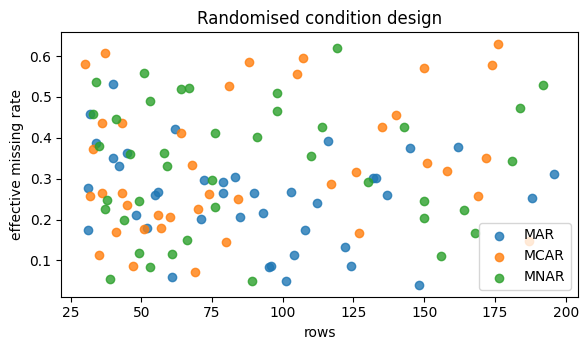

In [25]:
def find_csv(filename):
    for root in [Path.cwd(), Path.cwd() / "data", Path("/mnt/data")]:
        if (root / filename).is_file():
            return str((root / filename).resolve())
    return None

csv_paths = {k: p for k, fn in CSV_FILES.items() if (p := find_csv(fn))}
pool = mc.load_pool(csv_paths)
print("real data pool:", {k: v.shape for k, v in pool.items()})
conds = mc.make_conditions(CFG["n_cond"], SEED, pool, n_max=CFG["n_max"], p_max=CFG["p_max"])
cond_df = pd.DataFrame([c.meta for c in conds])
cond_df.to_csv(RESULTS_DIR / "conditions.csv", index=False)
np.savez_compressed(RESULTS_DIR / "conditions_data.npz", **{f"Xm_{c.cid}": c.Xm for c in conds},
                    **{f"Xtrue_{c.cid}": c.X_true for c in conds})
display(cond_df.round(3).head(12))
summary = pd.DataFrame({
    "conditions": [len(cond_df)],
    "sources": [cond_df.source.nunique()],
    "rows (min-max)": [f"{cond_df.n.min()}-{cond_df.n.max()}"],
    "columns (min-max)": [f"{cond_df.p.min()}-{cond_df.p.max()}"],
    "effective missing rate (min-max)": [f"{cond_df.rate_eff.min():.2f}-{cond_df.rate_eff.max():.2f}"],
    "tie-heavy (tie_frac>0.05)": [int((cond_df.tie_frac > 0.05).sum())],
})
display(summary)
display(cond_df.groupby("mechanism")[["rate_eff", "n", "p", "tie_frac"]].mean().round(3).join(cond_df.mechanism.value_counts().rename("count")))
display(cond_df[[c for c in cond_df.columns if c.startswith("flag_")]].sum().rename("conditions with stressor").to_frame().T)
fig, ax = plt.subplots(figsize=(6, 3.6))
for mech, g in cond_df.groupby("mechanism"):
    ax.scatter(g.n, g.rate_eff, label=mech, alpha=.8)
ax.set_xlabel("rows"); ax.set_ylabel("effective missing rate"); ax.legend(); ax.set_title("Randomised condition design")
fig.tight_layout(); fig.savefig(RESULTS_DIR / "figures" / "conditions.png", dpi=150); plt.show()

## 4. Mutant generation from the real source code

The engine parses the library source, enumerates **single-point** mutations in the functions listed above and rebuilds a private copy of the module with exactly one change. The catalogue follows the operator families of general-purpose Python mutation tools (comparison, arithmetic, boolean, constant, statement-deletion operators, as in Cosmic Ray / MutPy) and adds numerical-code operators: reduction swaps (`mean`↔`median`, `min`↔`max`, `argmin`↔`argmax`), NaN-awareness removal (`nanmean`→`mean`, `isnan`→`isinf`), dtype downgrades (`FLOAT_DTYPES`→float32-only, `float64`→`float32`), keyword removal (`dtype=`, `axis=`, `copy=`, `ensure_all_finite=`), tolerance scaling (float constants ×10 / ÷10) and strategy-string swaps.

An in-process engine is used instead of calling an external tool because each "test" here is a property suite that needs the returned arrays of two or more executions across hundreds of randomised conditions; running one external process per mutant would not give per-condition verdicts or deviations. The operator catalogue is deliberately the standard one so that the mutant population is not tailored to the properties under evaluation.

In [26]:
all_mutants, target_files = [], {}
for t, cfg in mc.TARGETS.items():
    src, path = mm.module_source(cfg["module"])
    target_files[t] = path
    ms = mm.enumerate_mutants(src, cfg["module"], t, cfg["funcs"])
    all_mutants += [m.asdict() for m in ms]
mut_df = pd.DataFrame(all_mutants)
print(f"{len(mut_df)} mutants enumerated")
display(pd.crosstab(mut_df.target, mut_df.category).assign(total=lambda d: d.sum(axis=1)))
display(mut_df.sample(10, random_state=SEED)[["mutant_id", "func", "lineno", "operator", "category", "original", "replacement"]])

864 mutants enumerated


category,arithmetic,axis,boundary,branch,constant,copy,dtype,kwarg,logical,nan,reduction,relational,semantic,statement,tie,tolerance,validation,total
target,,,,,,,,,,,,,,,,,,
IterativeImputer,24,10,12,42,74,2,3,26,47,1,3,36,2,107,3,0,13,405
KNNImputer,4,5,0,10,24,2,5,4,20,3,2,2,1,34,0,2,21,139
SimpleImputer,2,4,0,34,44,2,5,5,22,0,3,20,4,42,0,0,24,211
SoftImpute,6,1,1,3,4,0,1,5,4,3,1,1,0,12,0,5,0,47
nan_euclidean,8,0,0,5,14,1,0,4,5,0,0,4,0,15,0,1,5,62


,mutant_id,func,lineno,operator,category,original,replacement
34,SimpleImputer#0034,SimpleImputer._validate_input,369,Stmt[delete],validation,"_check_inputs_dtype(X, self.missing_values)",pass
343,KNNImputer#0132,KNNImputer.transform,380,Branch[negate If],branch,"if self.keep_empty_features: Xc = X Xc[:, ~val...","if not self.keep_empty_features: Xc = X Xc[:, ..."
269,KNNImputer#0058,KNNImputer.transform,274,Kwarg[drop accept_sparse],validation,"validate_data(self, X, accept_sparse=False, dt...","validate_data(self, X, dtype=FLOAT_DTYPES, for..."
369,nan_euclidean#0019,nan_euclidean_distances,552,Stmt[delete],statement,"distances = euclidean_distances(X, Y, squared=...",pass
659,IterativeImputer#0247,IterativeImputer.fit_transform,786,Stmt[delete],validation,"self.random_state_ = getattr(self, 'random_sta...",pass
723,IterativeImputer#0311,IterativeImputer.fit_transform,851,Bin[Add->Sub],arithmetic,self.max_iter + 1,self.max_iter - 1
495,IterativeImputer#0083,IterativeImputer._impute_one_feature,469,Kwarg[drop column_indexer],kwarg,"_safe_assign(X_filled, imputed_values, row_ind...","_safe_assign(X_filled, imputed_values, row_ind..."
769,IterativeImputer#0357,IterativeImputer.transform,921,Stmt[delete],statement,"X, Xt, mask_missing_values, complete_mask = se...",pass
183,SimpleImputer#0183,SimpleImputer.transform,670,Stmt[delete],validation,coordinates = np.where(mask_valid_features.tra...,pass
733,IterativeImputer#0321,IterativeImputer.fit_transform,880,Unary[remove-not],logical,not self.sample_posterior,self.sample_posterior


## 5. Reference behaviour of the unmutated libraries (and line coverage)

The unmutated implementations are executed on every condition. This single pass serves two purposes:

1. **Coverage.** Source lines executed by the workload are recorded; mutants in statements that are never executed (sparse branches, unused strategies, error paths not triggered) are labelled `NO_COVERAGE` and excluded from scoring.
2. **Reference gate.** Properties that the *real library* violates are **findings, not harness errors**. A mutant is only credited with a kill on a condition where the unmutated implementation satisfies the same property. Properties are never silently assumed valid: the table below shows how often each one is a valid oracle for each subject.

Only an exception raised by the property code itself (`PROPERTY_BUG`) stops the notebook.

In [27]:
from joblib import Parallel, delayed
t0 = time.time()
trace_by_subject = {sid: sorted({target_files[t] for t, cfg in mc.TARGETS.items() if sid in cfg["subjects"]}) for sid in mc.SUBJECTS}
ref_out = Parallel(n_jobs=min(N_JOBS, len(mc.SUBJECTS)))(
    delayed(mc.reference_task)([sid], conds, trace_by_subject[sid]) for sid in mc.SUBJECTS)
ref_rows = [r for rows, _, _ in ref_out for r in rows]
ref_time = {sid: el for sid, (_, _, el) in zip(mc.SUBJECTS, ref_out)}
covered_lines = {}
for _, lines, _ in ref_out:
    for f, ls in lines.items():
        covered_lines.setdefault(f, set()).update(ls)
ref_df = pd.DataFrame(ref_rows, columns=["sid", "cid", "pid", "dev", "err"])
ref_df["tol"] = ma.tol_series(ref_df["pid"], ref_df["sid"])
ref_df["violated"] = (ref_df["dev"] > ref_df["tol"]) | (ref_df["err"] != "")
ref_df = ref_df.merge(cond_df, on="cid")
ref_df.to_csv(RESULTS_DIR / "reference_gate.csv", index=False)
bugs = ref_df[ref_df["err"].str.startswith("PROPERTY_BUG")]
if len(bugs):
    display(bugs.head()); raise AssertionError("A property raised an unexpected exception: fix the property, not the library.")
print(f"reference pass: {len(ref_df)} property checks in {time.time()-t0:.0f}s")

mut_df["covered"] = [any(l in covered_lines.get(target_files[t], ()) for l in range(a, b + 1))
                     for t, a, b in zip(mut_df.target, mut_df.stmt_start, mut_df.stmt_end)]
display(pd.crosstab(mut_df.target, mut_df.covered).rename(columns={False: "not covered", True: "covered"}))

reference pass: 10440 property checks in 137s


covered,not covered,covered
target,,
IterativeImputer,139,266
KNNImputer,2,137
SimpleImputer,72,139
SoftImpute,0,47
nan_euclidean,2,60


**Violation rate of each property on the unmutated library** (share of conditions; blank = not applicable)

pid,CI,OVP,NFO,RNG,StatRep,RP,FP,DR,SE,TE,PFS,CS,MV,DT,IV,CB,NN
IterativeImputer[BayesianRidge],0.00,0.00,0.00,,,0.00,,0.00,,,,,0.00,0.01,0.00,0.00,0.00
KNNImputer[distance],0.00,0.00,0.00,0.00,,0.39,0.52,0.00,0.73,0.72,,,0.00,0.82,0.00,,
KNNImputer[uniform],0.00,0.00,0.00,0.00,,0.41,0.33,0.00,0.53,0.53,,,0.00,0.62,0.00,,
SimpleImputer[mean],0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,,
SimpleImputer[median],0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,,
SimpleImputer[most_frequent],0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,,
SoftImpute[custom],0.00,0.00,0.00,,,0.07,0.08,0.00,0.08,,,,,,0.00,,


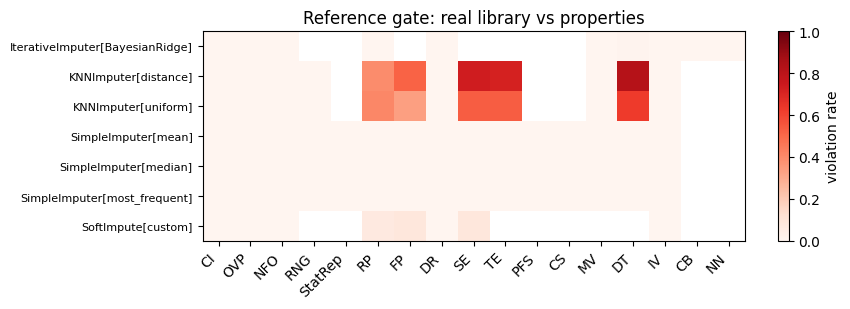

**Natural behaviour findings** — properties that the unmutated real library violates (to be explained, not hidden):

,subject,property,violated_conditions,of,rate,mean tie_frac (violating),mean tie_frac (holding),share with ties>5% (violating),smallest violating n,example cid,max deviation
0,IterativeImputer[BayesianRidge],DT,1,120,0.008,0.694,0.471,1.000,43,42,0.003
1,KNNImputer[distance],DT,98,120,0.817,0.490,0.396,0.827,30,0,1.174
2,KNNImputer[distance],FP,62,120,0.517,0.615,0.321,0.968,30,0,1.333
3,KNNImputer[distance],RP,47,120,0.392,0.758,0.289,0.979,30,2,1.600
4,KNNImputer[distance],SE,88,120,0.733,0.605,0.110,0.943,30,0,1.333
5,KNNImputer[distance],TE,86,120,0.717,0.592,0.173,0.930,30,2,1.247
6,KNNImputer[uniform],DT,75,120,0.625,0.586,0.285,0.907,30,0,0.859
7,KNNImputer[uniform],FP,40,120,0.333,0.735,0.342,1.000,34,4,0.800
8,KNNImputer[uniform],RP,49,120,0.408,0.760,0.275,0.980,30,2,1.600
9,KNNImputer[uniform],SE,64,120,0.533,0.709,0.203,0.984,30,2,0.800


**Weak oracles (valid on fewer than half of the conditions):** these pairs contribute few eligible checks.

,sid,pid,valid_oracle_share
12,KNNImputer[distance],DT,0.18
13,KNNImputer[distance],FP,0.48
20,KNNImputer[distance],SE,0.27
21,KNNImputer[distance],TE,0.28
24,KNNImputer[uniform],DT,0.38
32,KNNImputer[uniform],SE,0.47
33,KNNImputer[uniform],TE,0.47


In [28]:
rate = (ref_df.groupby(["sid", "pid"]).violated.mean().unstack("pid").reindex(columns=mc.PROP_IDS))
rate.index = [i for i in rate.index]
display(Markdown("**Violation rate of each property on the unmutated library** (share of conditions; blank = not applicable)"))
display(rate.round(2).style.background_gradient(cmap="Reds", vmin=0, vmax=1).format("{:.2f}", na_rep=""))
fig, ax = plt.subplots(figsize=(9, 3.2))
im = ax.imshow(rate.to_numpy(float), cmap="Reds", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(rate.columns))); ax.set_xticklabels(rate.columns, rotation=45, ha="right")
ax.set_yticks(range(len(rate.index))); ax.set_yticklabels(rate.index, fontsize=8)
fig.colorbar(im, label="violation rate"); ax.set_title("Reference gate: real library vs properties")
fig.tight_layout(); fig.savefig(RESULTS_DIR / "figures" / "reference_gate.png", dpi=150); plt.show()

nat = []
for (sid, pid), g in ref_df.groupby(["sid", "pid"]):
    if g.violated.any():
        v, ok = g[g.violated], g[~g.violated]
        nat.append({"subject": sid, "property": pid, "violated_conditions": int(g.violated.sum()), "of": len(g),
                    "rate": g.violated.mean(), "mean tie_frac (violating)": v.tie_frac.mean(),
                    "mean tie_frac (holding)": ok.tie_frac.mean() if len(ok) else np.nan,
                    "share with ties>5% (violating)": (v.tie_frac > .05).mean(),
                    "smallest violating n": int(v.n.min()), "example cid": int(v.cid.iloc[0]),
                    "max deviation": float(v.dev.replace(np.inf, np.nan).max())})
natural = pd.DataFrame(nat)
natural.to_csv(RESULTS_DIR / "natural_behaviour_findings.csv", index=False)
display(Markdown("**Natural behaviour findings** — properties that the unmutated real library violates (to be explained, not hidden):"))
display(natural.round(3) if len(natural) else "No property was violated by an unmutated implementation.")
valid = (1 - ref_df.groupby(["sid", "pid"]).violated.mean()).rename("valid_oracle_share").reset_index()
weak = valid[valid.valid_oracle_share < 0.5]
if len(weak):
    display(Markdown("**Weak oracles (valid on fewer than half of the conditions):** these pairs contribute few eligible checks."))
    display(weak.round(2))

## 6. Mutant selection

A mutant is evaluated only if its statement is covered. With a cap (`quick`/`medium`) the covered mutants of each target are sampled **round-robin across operator categories** (so rare, subtle categories such as tolerance, NaN and dtype are not drowned by statement deletions). The `full` profile evaluates every covered mutant.

In [29]:
def stratified_pick(df, cap, seed):
    if cap is None or len(df) <= cap:
        return list(df.index)
    rng = np.random.default_rng(seed)
    groups = {k: list(rng.permutation(g.index)) for k, g in df.groupby("category")}
    chosen = []
    while len(chosen) < cap:
        progressed = False
        for k in sorted(groups):
            if groups[k] and len(chosen) < cap:
                chosen.append(groups[k].pop()); progressed = True
        if not progressed:
            break
    return chosen

mut_df["selected"] = False
for i, (t, g) in enumerate(mut_df[mut_df.covered].groupby("target")):
    mut_df.loc[stratified_pick(g, CFG["mutant_cap"], SEED + i), "selected"] = True
display(pd.crosstab(mut_df.target, [mut_df.covered, mut_df.selected]).rename_axis(columns=["covered", "selected"]))
display(pd.crosstab(mut_df[mut_df.selected].target, mut_df[mut_df.selected].category))

covered,False,True
selected,False,True
target,,
IterativeImputer,139,266
KNNImputer,2,137
SimpleImputer,72,139
SoftImpute,0,47
nan_euclidean,2,60


category,arithmetic,axis,boundary,branch,constant,copy,dtype,kwarg,logical,nan,reduction,relational,semantic,statement,tie,tolerance,validation
target,,,,,,,,,,,,,,,,,
IterativeImputer,6,10,7,34,50,2,2,18,32,1,3,27,1,59,2,0,12
KNNImputer,4,5,0,10,24,2,5,4,20,3,2,2,1,34,0,2,19
SimpleImputer,1,3,0,24,28,1,2,4,13,0,3,16,4,25,0,0,15
SoftImpute,6,1,1,3,4,0,1,5,4,3,1,1,0,12,0,5,0
nan_euclidean,8,0,0,5,14,1,0,4,5,0,0,4,0,14,0,0,5


## 7. Main experiment

Every selected mutant is run on every subject that executes its code and on every condition, with all applicable properties. For each (mutant, subject, condition, property) we store the reference deviation, the mutant deviation and any exception. Alongside, an *activation record* stores whether the mutant changed **any** observable output of that condition (original run or any follow-up run) and by how much.

Faulty library code can hang inside native routines that no in-process timeout can interrupt (for example LAPACK given non-finite values), so tasks run in a **supervised process pool with a hard wall-clock limit**. The infinite-input check (`IV`) is isolated in its own task: if a mutant hangs on it, the `IV` property is recorded as violated for that subject (the reference raises `ValueError`).

Per-target results are cached in the results folder (`RESUME=True`), so an interrupted full run can be resumed.

In [30]:
CODE_HASH = hashlib.sha1("".join(Path(f).read_text() for f in ("mt_mutate.py", "mt_core.py", "mt_softimpute.py")).encode()).hexdigest()

def signature(target, ids):
    blob = json.dumps({"profile": PROFILE, "cfg": CFG, "seed": SEED, "sklearn": sklearn.__version__, "code": CODE_HASH,
                       "ids": ids, "n_cond": len(conds)}, sort_keys=True)
    return hashlib.sha1(blob.encode()).hexdigest()

ref_iv_ok = {sid: ref_df[(ref_df.sid == sid) & (ref_df.pid == "IV") & (ref_df.dev <= 0) & (ref_df.err == "")].cid.tolist()
             for sid in mc.SUBJECTS}
# hard wall-clock limit per task: a mutated library may hang in native code (e.g. LAPACK given inf)
HARD = {sid: {"main": max(120.0, 10 * ref_time[sid]), "iv": max(60.0, 0.5 * ref_time[sid])} for sid in mc.SUBJECTS}

def run_target(t):
    sel = mut_df[(mut_df.target == t) & mut_df.selected]
    ids = sel.mutant_id.tolist()
    cache = RESULTS_DIR / f"raw_{t}.pkl"
    sig = signature(t, ids)
    if RESUME and cache.exists():
        old = pd.read_pickle(cache)
        if old["sig"] == sig:
            print(f"[{t}] loaded from cache ({len(ids)} mutants)"); return old["P"], old["E"], old["S"]
    records = sel.drop(columns=["covered", "selected"]).to_dict("records")
    tasks = [dict(tid=f"{mu['mutant_id']}|{sid}|{phase}", mu=mu, sid=sid, phase=phase, hard=HARD[sid][phase])
             for mu in records for sid in mc.TARGETS[t]["subjects"] for phase in ("main", "iv")]
    t0 = time.time()
    out = mc.run_supervised(tasks, conds, n_workers=N_JOBS, label=t)
    prows, erows, srows = [], [], []
    for tid, (kind, payload) in out.items():
        mid, sid, phase = tid.split("|")
        if kind == "ok":
            pr, er, st = payload
            prows += pr; erows += er; srows.append((mid, st[0], st[1]))
        elif kind == "error":
            raise RuntimeError(f"worker error on {tid}: {payload}")
        elif phase == "main":                       # hang / process death while running ordinary inputs
            srows.append((mid, "TIMEOUT", f"{sid}: {kind}"))
        else:                                       # hang on infinite input: the IV property is violated everywhere
            srows.append((mid, "OK", f"{sid}: IV hang"))
            for cid in ref_iv_ok[sid]:
                prows.append((mid, sid, cid, "IV", 0.0, float("inf"), ""))
                erows.append((mid, sid, cid, "iv", True, float("inf"), 0.0, "", 0))
    P = pd.DataFrame(prows, columns=["mutant_id", "sid", "cid", "pid", "ref_dev", "mut_dev", "mut_err"])
    E = pd.DataFrame(erows, columns=["mutant_id", "sid", "cid", "phase", "differs", "base_mag", "any_mag", "base_exc", "n_exc"])
    S = pd.DataFrame(srows, columns=["mutant_id", "status", "detail"])
    pd.to_pickle({"sig": sig, "P": P, "E": E, "S": S}, cache)
    print(f"[{t}] {len(ids)} mutants, {len(tasks)} tasks: {len(P)} property rows, {(S.status == 'TIMEOUT').sum()} timeouts, "
          f"{(S.detail.str.contains('IV hang')).sum()} IV hangs, {time.time()-t0:.0f}s")
    return P, E, S

t_all = time.time()
parts = [run_target(t) for t in mc.TARGETS]
P = pd.concat([p[0] for p in parts], ignore_index=True)
E = pd.concat([p[1] for p in parts], ignore_index=True)
S = pd.concat([p[2] for p in parts], ignore_index=True)
P["tol"] = ma.tol_series(P["pid"], P["sid"])
print(f"total {len(P)} property rows, {len(E)} activation rows, elapsed {(time.time()-t_all)/60:.1f} min")
P.to_csv(RESULTS_DIR / "mutation_property_rows.csv.gz", index=False)
E.to_csv(RESULTS_DIR / "mutation_activation_rows.csv.gz", index=False)

  [SimpleImputer] 45/834 tasks | 0.5 min
  [SimpleImputer] 105/834 tasks | 1.0 min
  [SimpleImputer] 180/834 tasks | 1.5 min
  [SimpleImputer] 273/834 tasks | 2.0 min
  [SimpleImputer] 378/834 tasks | 2.5 min
  [SimpleImputer] 465/834 tasks | 3.0 min
  [SimpleImputer] 557/834 tasks | 3.5 min
  [SimpleImputer] 645/834 tasks | 4.0 min
  [SimpleImputer] 746/834 tasks | 4.5 min
[SimpleImputer] 139 mutants, 834 tasks: 750600 property rows, 0 timeouts, 0 IV hangs, 302s
  [KNNImputer] 15/548 tasks | 0.5 min
  [KNNImputer] 61/548 tasks | 1.0 min
  [KNNImputer] 109/548 tasks | 1.5 min
  [KNNImputer] 197/548 tasks | 2.0 min
  [KNNImputer] 273/548 tasks | 2.5 min
  [KNNImputer] 371/548 tasks | 3.0 min
  [KNNImputer] 445/548 tasks | 3.5 min
  [KNNImputer] 525/548 tasks | 4.0 min
[KNNImputer] 137 mutants, 548 tasks: 307428 property rows, 0 timeouts, 0 IV hangs, 256s
  [nan_euclidean] 15/240 tasks | 0.5 min
  [nan_euclidean] 59/240 tasks | 1.0 min
  [nan_euclidean] 115/240 tasks | 1.5 min
  [nan_euc

## 8. Mutant outcome classes

Every mutant ends in exactly one class, assigned in this order:

| Class | Meaning | In the score? |
|---|---|---|
| `NO_COVERAGE` | statement never executed by the workload | no |
| `NOT_SAMPLED` | covered but outside the cap (quick/medium only) | no |
| `STILLBORN` | the mutated module cannot even be built | no |
| `TIMEOUT` | hangs (hard wall-clock limit) on ordinary inputs and is not killed by a property | no (reported) |
| `EQUIV_CANDIDATE` | no observable output changed in any execution of any condition (equivalent, or not reached by this workload; needs manual audit) | no |
| `CRASH_ALL` | the baseline execution raises on every condition — any test would see it, no oracle is needed | no (reported) |
| `KILLED_PROP` | at least one property is violated where the unmutated library satisfies it | **yes** |
| `KILLED_CRASH` | exceptions on some conditions, but no property violation | yes, as non-property kill |
| `SURVIVED` | behaviour changed but no property violation and no exception | yes |

The **property-based mutation score** is `KILLED_PROP / (KILLED_PROP + KILLED_CRASH + SURVIVED)`; the stricter reading never credits exceptions.

In [31]:
cls_df = ma.classify(mut_df, P, E, S)
cls_df.to_csv(RESULTS_DIR / "mutant_classification.csv", index=False)
census = pd.crosstab(cls_df.target, cls_df["class"]).reindex(columns=ma.CLASS_ORDER, fill_value=0)
census["total"] = census.sum(axis=1)
display(census)
analysed = cls_df[cls_df["class"].isin(ma.ANALYSED)]
analysed_ids = analysed.mutant_id.tolist()
print(f"{len(analysed)} non-trivial behaviour-changing mutants enter the analysis")

class,NO_COVERAGE,NOT_SAMPLED,STILLBORN,TIMEOUT,EQUIV_CANDIDATE,CRASH_ALL,KILLED_PROP,KILLED_CRASH,SURVIVED,total
target,,,,,,,,,,
IterativeImputer,139,0,0,0,76,111,19,32,28,405
KNNImputer,2,0,0,0,26,54,48,7,2,139
SimpleImputer,72,0,0,0,43,44,31,21,0,211
SoftImpute,0,0,0,0,9,15,19,1,3,47
nan_euclidean,2,0,0,0,8,15,32,4,1,62


248 non-trivial behaviour-changing mutants enter the analysis


## 9. RQ1 — How well do the properties detect faults in real library code?

Mutation scores with 95% bootstrap confidence intervals (resampling **mutants**, the unit of analysis). The breakdown by *fault family* addresses the subtle classes (tolerance, NaN handling, dtype, neighbour/tie selection); family labels are assigned by a transparent keyword rule on the mutated statement (`mt_analysis.subtle_family`) and should be read as exploratory.

**Overall (strict: exceptions are not credited)**

,scope,mutants,analysed,killed_by_property,killed_by_crash_only,survived,score,ci_lo,ci_hi
0,all targets,864,248,149,65,34,0.601,0.536,0.661


**Overall (lenient: exceptions credited)**

,scope,mutants,analysed,killed_by_property,killed_by_crash_only,survived,score,ci_lo,ci_hi
0,all targets,864,248,149,65,34,0.863,0.819,0.907


**By mutated source**

,target,mutants,analysed,killed_by_property,killed_by_crash_only,survived,score,ci_lo,ci_hi
0,IterativeImputer,405,79,19,32,28,0.241,0.152,0.342
1,KNNImputer,139,57,48,7,2,0.842,0.737,0.930
2,SimpleImputer,211,52,31,21,0,0.596,0.462,0.731
3,SoftImpute,47,23,19,1,3,0.826,0.652,0.957
4,nan_euclidean,62,37,32,4,1,0.865,0.730,0.973


**By subtle fault family**

,subtle_family,mutants,analysed,killed_by_property,killed_by_crash_only,survived,score,ci_lo,ci_hi
0,NaN / mask,365,120,76,32,12,0.633,0.550,0.717
1,dtype,80,10,8,0,2,0.800,0.500,1.000
2,other logic,312,73,35,24,14,0.479,0.370,0.589
3,tie / neighbour selection,43,22,19,2,1,0.864,0.727,1.000
4,tolerance / numeric,64,23,11,7,5,0.478,0.261,0.696


**By operator category**

,category,mutants,analysed,killed_by_property,killed_by_crash_only,survived,score,ci_lo,ci_hi
4,constant,160,45,28,11,6,0.622,0.489,0.756
13,statement,210,45,20,22,3,0.444,0.289,0.600
3,branch,94,32,20,7,5,0.625,0.469,0.781
8,logical,98,29,21,4,4,0.724,0.552,0.862
11,relational,63,21,10,6,5,0.476,0.286,0.667
0,arithmetic,44,20,14,0,6,0.700,0.500,0.900
7,kwarg,44,14,10,3,1,0.714,0.500,0.929
16,validation,63,8,2,5,1,0.250,0.000,0.625
9,nan,7,7,6,1,0,0.857,0.571,1.000
10,reduction,9,6,4,1,1,0.667,0.333,1.000


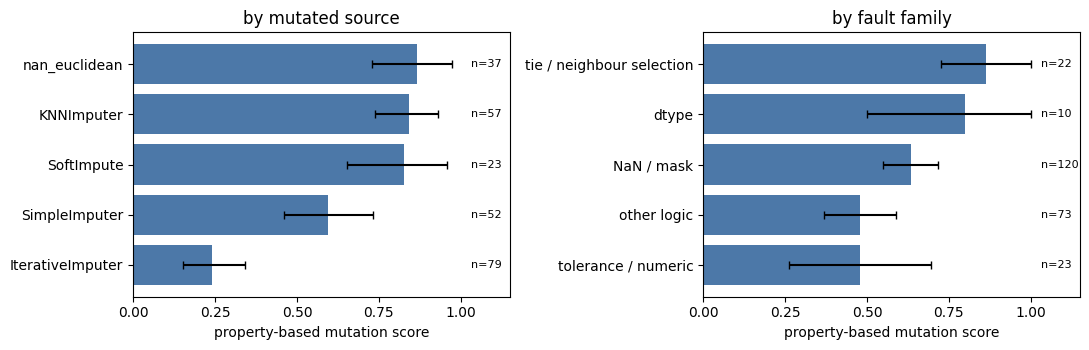

In [32]:
nb = CFG["n_boot"]
overall = ma.score_table(cls_df.assign(scope="all targets"), ["scope"], nb)
by_target = ma.score_table(cls_df, ["target"], nb)
by_family = ma.score_table(cls_df, ["subtle_family"], nb)
by_cat = ma.score_table(cls_df, ["category"], nb).sort_values("analysed", ascending=False)
by_op = ma.score_table(cls_df, ["target", "category"], nb)
lenient = ma.score_table(cls_df.assign(scope="all targets"), ["scope"], nb, include_crash=True)
for name, tb in [("rq1_overall", overall), ("rq1_by_target", by_target), ("rq1_by_family", by_family),
                 ("rq1_by_category", by_cat), ("rq1_by_target_category", by_op)]:
    tb.to_csv(RESULTS_DIR / f"{name}.csv", index=False)
display(Markdown("**Overall (strict: exceptions are not credited)**")); display(overall.round(3))
display(Markdown("**Overall (lenient: exceptions credited)**")); display(lenient.round(3))
display(Markdown("**By mutated source**")); display(by_target.round(3))
display(Markdown("**By subtle fault family**")); display(by_family.round(3))
display(Markdown("**By operator category**")); display(by_cat.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True)
for ax, tb, col, title in [(axes[0], by_target, "target", "by mutated source"), (axes[1], by_family, "subtle_family", "by fault family")]:
    tb = tb.sort_values("score")
    ax.barh(tb[col], tb.score, xerr=[tb.score - tb.ci_lo, tb.ci_hi - tb.score], capsize=3, color="#4C78A8")
    for y, n in enumerate(tb.analysed):
        ax.text(1.03, y, f"n={n}", va="center", fontsize=8)
    ax.set_xlim(0, 1.15); ax.set_xticks([0, .25, .5, .75, 1]); ax.set_xlabel("property-based mutation score"); ax.set_title(title)
fig.tight_layout(); fig.savefig(RESULTS_DIR / "figures" / "rq1_scores.png", dpi=150); plt.show()

## 10. RQ2 — Which properties are necessary, and which are redundant?

From the kill matrix (mutant × property, `True` if the property is violated on some condition where the reference satisfies it) we compute, per scope: kills per property, **unique kills** (mutants only that property kills), the loss if the property were removed, the **exact smallest property subsets** that preserve all kills of the full suite, a greedy order, and the comparison of the **original 7-property suite** with the extended suite. A bootstrap over mutants estimates how often each property appears in a minimal set.

*Note on `StatRep`:* it generalises the original `MeanRep` (duplicate a row, compare imputed cells with the closed-form statistic of the augmented column) to the median and most-frequent strategies; for mean imputation it is identical to `MeanRep`.

**Kills per property (all targets)**

,property,class,kills,unique_kills,lost_if_removed
0,RP,metamorphic,52,7,7
1,StatRep,analytic oracle,27,7,7
2,DT,metamorphic,38,6,6
3,NN,metamorphic,10,6,6
4,SE,metamorphic,55,5,5
5,NFO,invariant,39,4,4
6,IV,robustness,5,4,4
7,MV,metamorphic,33,3,3
8,CB,invariant,3,3,3
9,TE,metamorphic,45,2,2


**Exact minimal property sets that keep every kill of the full suite**

,scope,analysed,killable_by_full_suite,min_suite_size,n_minimal_sets,example_minimal_set
0,ALL,248,149,11,1,CI + NFO + StatRep + RP + SE + TE + MV + DT + ...
1,SimpleImputer,52,31,2,1,StatRep + IV
2,KNNImputer,57,48,5,1,CI + RNG + RP + SE + MV
3,nan_euclidean,37,32,3,1,RP + TE + DT
4,IterativeImputer,79,19,4,1,MV + DT + CB + NN
5,SoftImpute,23,19,3,1,NFO + SE + IV


**Original 7-property suite versus extended suite** (share of analysed mutants killed)

,scope,analysed,original 7,extended 17,only the 10 new
0,ALL,248,0.371,0.601,0.464
1,SimpleImputer,52,0.519,0.596,0.462
2,KNNImputer,57,0.421,0.842,0.632
3,nan_euclidean,37,0.676,0.865,0.838
4,IterativeImputer,79,0.025,0.241,0.241
5,SoftImpute,23,0.609,0.826,0.217


**Greedy property order (cumulative mutants killed)**

[('SE', 55), ('NFO', 94), ('RP', 106), ('TE', 116), ('DT', 125), ('StatRep', 132), ('NN', 138), ('IV', 142), ('MV', 145), ('CB', 148), ('CI', 149)]


**Stability.** Minimal-set size over bootstrap resamples: median 11 (5-95%: 10-11)

,property,in_a_minimal_set (bootstrap share)
5,RP,1.00
16,NN,1.00
13,DT,1.00
4,StatRep,1.00
2,NFO,1.00
8,SE,0.99
14,IV,0.99
15,CB,0.95
12,MV,0.94
9,TE,0.89


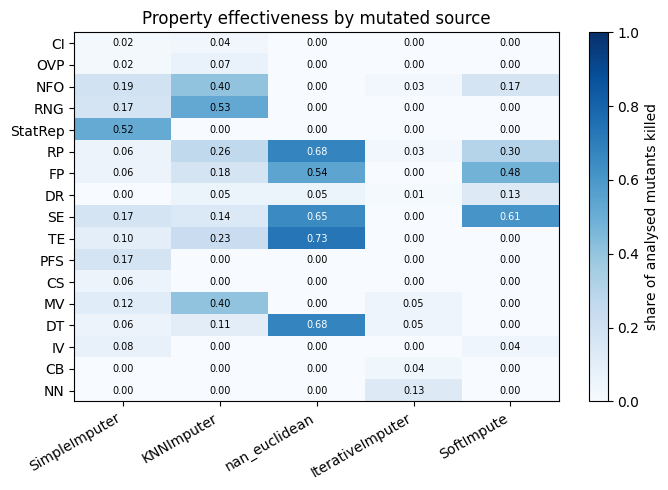

In [33]:
scopes = {"ALL": analysed_ids}
for t in mc.TARGETS:
    ids = analysed[analysed.target == t].mutant_id.tolist()
    if ids: scopes[t] = ids
K_all = ma.kill_matrix(P, analysed_ids)
K_all.to_csv(RESULTS_DIR / "kill_matrix.csv")
contrib = {}
suite_rows, cover_rows = [], []
for scope, ids in scopes.items():
    K = K_all.loc[ids]
    contrib[scope] = ma.property_contributions(K)
    k, sols, n_sols = ma.minimal_covers(K)
    cover_rows.append({"scope": scope, "analysed": len(ids), "killable_by_full_suite": int(K.any(axis=1).sum()),
                       "min_suite_size": k, "n_minimal_sets": n_sols, "example_minimal_set": " + ".join(sols[0]) if sols else ""})
    suite_rows.append({"scope": scope, "analysed": len(ids), "original 7": ma.suite_score(K, mc.PAPER7),
                       f"extended {len(mc.PROP_IDS)}": ma.suite_score(K, mc.PROP_IDS),
                       f"only the {len(mc.PROP_IDS) - len(mc.PAPER7)} new": ma.suite_score(K, [p for p in mc.PROP_IDS if p not in mc.PAPER7])})
display(Markdown("**Kills per property (all targets)**")); display(contrib["ALL"])
display(Markdown("**Exact minimal property sets that keep every kill of the full suite**")); display(pd.DataFrame(cover_rows))
display(Markdown("**Original 7-property suite versus extended suite** (share of analysed mutants killed)")); display(pd.DataFrame(suite_rows).round(3))
pd.DataFrame(cover_rows).to_csv(RESULTS_DIR / "rq2_minimal_sets.csv", index=False)
pd.DataFrame(suite_rows).to_csv(RESULTS_DIR / "rq2_suite_comparison.csv", index=False)
contrib["ALL"].to_csv(RESULTS_DIR / "rq2_property_contributions.csv", index=False)
display(Markdown("**Greedy property order (cumulative mutants killed)**")); print(ma.greedy_order(K_all))

# stability of the minimal set under resampling of mutants
rng = np.random.default_rng(SEED)
M = K_all.to_numpy(); freq = np.zeros(M.shape[1]); sizes = []
for b in range(min(300, CFG["n_boot"])):
    idx = rng.integers(0, len(K_all), len(K_all))
    k, sols, _ = ma.minimal_covers(K_all.iloc[idx], limit=1)
    sizes.append(k)
    for p in (sols[0] if sols else []): freq[K_all.columns.get_loc(p)] += 1
stab = pd.DataFrame({"property": K_all.columns, "in_a_minimal_set (bootstrap share)": freq / max(1, len(sizes))})
display(Markdown(f"**Stability.** Minimal-set size over bootstrap resamples: median {np.median(sizes):.0f} "
                 f"(5-95%: {np.quantile(sizes, .05):.0f}-{np.quantile(sizes, .95):.0f})"))
display(stab.sort_values("in_a_minimal_set (bootstrap share)", ascending=False).round(2))

heat = pd.DataFrame({t: ma.kill_matrix(P, ids).mean() for t, ids in scopes.items() if t != "ALL"})
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(heat.to_numpy(float), cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(heat.shape[1])); ax.set_xticklabels(heat.columns, rotation=30, ha="right")
ax.set_yticks(range(heat.shape[0])); ax.set_yticklabels(heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat.iat[i, j]:.2f}", ha="center", va="center", fontsize=7, color="k" if heat.iat[i, j] < .6 else "w")
fig.colorbar(im, label="share of analysed mutants killed"); ax.set_title("Property effectiveness by mutated source")
fig.tight_layout(); fig.savefig(RESULTS_DIR / "figures" / "rq2_property_heatmap.png", dpi=150); plt.show()

## 11. RQ3 — Is detection condition-dependent? (the determinism question)

For every (mutant, subject) pair we estimate **P(property violation | the fault changed the output on that condition)** across the randomised conditions. If outcomes were deterministic this distribution would sit at 0 and 1. We report the share of intermediate probabilities, the effect of each condition factor (with bootstrap CIs over mutants), a paired test between missingness mechanisms, a **condition-budget curve** (how many conditions are needed before the score saturates) and two reliability checks (bootstrap over conditions and split-half agreement) that quantify how much the result depends on which random conditions were drawn.

**291 (mutant, subject) pairs** with at least 3 activated conditions

,pairs,share
regime,,
condition-dependent,112,0.385
always detected,103,0.354
never detected,76,0.261


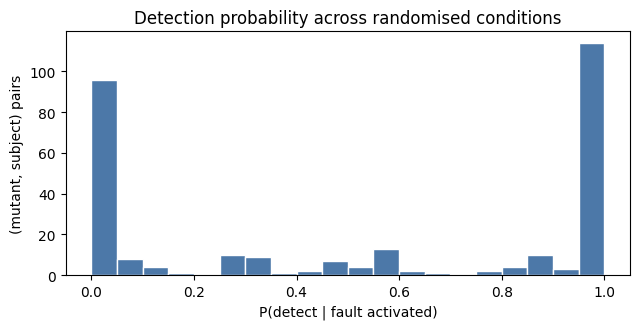

**Detection probability by condition factor** (mean over mutants activated in that stratum)

,factor,level,mutants,mean P(detect),ci_lo,ci_hi
0,mechanism,MAR,198,0.498,0.435,0.561
1,mechanism,MCAR,205,0.484,0.423,0.550
2,mechanism,MNAR,209,0.509,0.449,0.573
3,missing-rate bin,<=15%,182,0.484,0.418,0.552
4,missing-rate bin,15-30%,202,0.500,0.440,0.565
5,missing-rate bin,30-45%,205,0.494,0.434,0.560
6,missing-rate bin,>45%,206,0.491,0.433,0.551
7,rows bin,<=50,207,0.500,0.442,0.564
8,rows bin,51-100,210,0.503,0.443,0.568
9,rows bin,>100,203,0.494,0.432,0.555


**Paired comparison of missingness mechanisms** (per-mutant detection probability)

,comparison,mutants,mean diff,Wilcoxon p
0,MCAR vs MAR,198,-0.0018,0.1779
1,MCAR vs MNAR,198,-0.0143,0.0000
2,MAR vs MNAR,198,-0.0126,0.1360


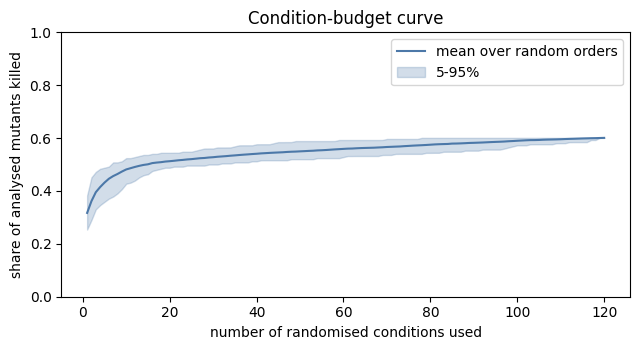

conditions needed to reach 50% / 80% / 95% of the final score (mean curve): {0.5: 1, 0.8: 10, 0.95: 76}


**Sensitivity to the random condition draw** — resampling conditions (bootstrap) and comparing disjoint random halves of the conditions. A resample can only repeat conditions, never add new ones, so the bootstrap lies below the observed score by construction (report its lower end); the split-half Spearman measures whether detectability is a stable property of each mutant rather than noise.

,score with all conditions (violation-based),condition-bootstrap median,condition-bootstrap 2.5%,split-half |score difference| (median),split-half Spearman of per-mutant detectability (median)
0,0.601,0.573,0.536,0.028,0.972


In [34]:
X = ma.detection_probability(P, E, analysed_ids)
pdet = X.groupby(["mutant_id", "sid"]).agg(n_activated=("killed", "size"), p_detect=("killed", "mean")).reset_index()
pdet = pdet[pdet.n_activated >= 3]
pdet["regime"] = np.where(pdet.p_detect == 0, "never detected", np.where(pdet.p_detect == 1, "always detected", "condition-dependent"))
pdet.to_csv(RESULTS_DIR / "rq3_detection_probability.csv", index=False)
display(Markdown(f"**{len(pdet)} (mutant, subject) pairs** with at least 3 activated conditions"))
display(pdet.regime.value_counts().rename("pairs").to_frame().assign(share=lambda d: d.pairs / d.pairs.sum()).round(3))
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.hist(pdet.p_detect, bins=np.linspace(0, 1, 21), color="#4C78A8", edgecolor="w")
ax.set_xlabel("P(detect | fault activated)"); ax.set_ylabel("(mutant, subject) pairs"); ax.set_title("Detection probability across randomised conditions")
fig.tight_layout(); fig.savefig(RESULTS_DIR / "figures" / "rq3_detection_probability.png", dpi=150); plt.show()

cd = cond_df.copy()
cd["missing-rate bin"] = pd.cut(cd.rate_eff, [0, .15, .3, .45, 1], labels=["<=15%", "15-30%", "30-45%", ">45%"])
cd["rows bin"] = pd.cut(cd.n, [0, 50, 100, 10**6], labels=["<=50", "51-100", ">100"])
cd["ties"] = np.where(cd.tie_frac > .05, "ties>5%", "tie-free")
cd["scale spread"] = np.where(cd.scale_spread >= 1.5, "heterogeneous (>=1.5 decades)", "homogeneous")
Xc = X.merge(cd, on="cid")
strata = []
for col in ["mechanism", "missing-rate bin", "rows bin", "ties", "scale spread", "flag_rescaled", "flag_coarse", "flag_dup_rows",
            "flag_const_col", "flag_empty_col", "flag_empty_row", "source"]:
    g = Xc.groupby(["mutant_id", col], observed=True).killed.mean().reset_index()
    for level, gg in g.groupby(col, observed=True):
        m, lo, hi = ma.boot_ci(gg.killed.to_numpy(float), CFG["n_boot"])
        strata.append({"factor": col, "level": str(level), "mutants": len(gg), "mean P(detect)": m, "ci_lo": lo, "ci_hi": hi})
strata = pd.DataFrame(strata)
strata.to_csv(RESULTS_DIR / "rq3_condition_factors.csv", index=False)
display(Markdown("**Detection probability by condition factor** (mean over mutants activated in that stratum)"))
display(strata.round(3))

from scipy.stats import wilcoxon
g = Xc.groupby(["mutant_id", "mechanism"]).killed.mean().unstack("mechanism").dropna()
tests = []
for a, b in [("MCAR", "MAR"), ("MCAR", "MNAR"), ("MAR", "MNAR")]:
    if a in g and b in g:
        d = (g[a] - g[b]).to_numpy()
        try: pval = wilcoxon(d).pvalue if np.any(d != 0) else 1.0
        except ValueError: pval = np.nan
        tests.append({"comparison": f"{a} vs {b}", "mutants": len(d), f"mean diff": d.mean(), "Wilcoxon p": pval})
display(Markdown("**Paired comparison of missingness mechanisms** (per-mutant detection probability)"))
display(pd.DataFrame(tests).round(4))

curves = ma.budget_curve(X, analysed_ids, list(cond_df.cid), n_perm=200, seed=SEED)
ks = np.arange(1, curves.shape[1] + 1)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(ks, curves.mean(axis=0), color="#4C78A8", label="mean over random orders")
ax.fill_between(ks, np.quantile(curves, .05, axis=0), np.quantile(curves, .95, axis=0), alpha=.25, color="#4C78A8", label="5-95%")
ax.set_xlabel("number of randomised conditions used"); ax.set_ylabel("share of analysed mutants killed"); ax.set_ylim(0, 1)
ax.legend(); ax.set_title("Condition-budget curve"); fig.tight_layout()
fig.savefig(RESULTS_DIR / "figures" / "rq3_budget_curve.png", dpi=150); plt.show()
need = {f: int(np.argmax(curves.mean(axis=0) >= f * curves.mean(axis=0)[-1]) + 1) for f in (.5, .8, .95)}
print("conditions needed to reach 50% / 80% / 95% of the final score (mean curve):", need)

# how much does the score depend on WHICH random conditions were drawn?
full_score, boot_scores = ma.condition_bootstrap(X, analysed_ids, list(cond_df.cid), n_boot=CFG["n_boot"], seed=SEED)
rho, dscore = ma.split_half(X, analysed_ids, list(cond_df.cid), seed=SEED)
reliab = pd.DataFrame([{
    "score with all conditions (violation-based)": full_score,
    "condition-bootstrap median": np.median(boot_scores), "condition-bootstrap 2.5%": np.quantile(boot_scores, .025),
    "split-half |score difference| (median)": np.median(dscore),
    "split-half Spearman of per-mutant detectability (median)": np.nanmedian(rho) if len(rho) else np.nan}])
reliab.to_csv(RESULTS_DIR / "rq3_condition_sampling_reliability.csv", index=False)
display(Markdown("**Sensitivity to the random condition draw** — resampling conditions (bootstrap) and comparing disjoint random halves of the conditions. "
                 "A resample can only repeat conditions, never add new ones, so the bootstrap lies below the observed score by construction (report its lower end); "
                 "the split-half Spearman measures whether detectability is a stable property of each mutant rather than noise."))
display(reliab.round(3))

## 12. RQ4 — Subtle faults, tolerance sensitivity and survivors

* **Strength versus fault subtlety.** The magnitude of the output change a mutant causes (largest scaled deviation over its activated executions) is binned; if properties are only sensitive to gross faults, the score will fall with magnitude.
* **Tolerance sensitivity.** Every deviation is stored, so the score can be recomputed without re-running anything at tolerances ×0.01, ×1 and ×100 (the reference gate is re-applied each time).
* **Survivors.** The mutants that survive are exported for manual audit; some may be equivalent. The automatic `EQUIV_CANDIDATE` class only means "no observable change in this workload".

In [35]:
Ef = E[E.mutant_id.isin(analysed_ids)].copy()
Ef["mag"] = np.where(np.isfinite(Ef.base_mag), np.maximum(Ef.base_mag, Ef.any_mag), Ef.any_mag)
Ef["has_inf"] = ~np.isfinite(Ef.base_mag)
mag = Ef.groupby("mutant_id").agg(mag_max=("mag", "max"), structural=("has_inf", "any")).reset_index()
bins = [-1, 1e-9, 1e-6, 1e-3, 1e-1, np.inf]
labels = ["<=1e-9", "1e-9..1e-6", "1e-6..1e-3", "1e-3..0.1", ">0.1"]
mag["magnitude"] = pd.cut(mag.mag_max, bins, labels=labels).astype(object)
mag.loc[mag.structural & (mag.mag_max <= 0), "magnitude"] = "structural (exception, NaN pattern or shape)"
mm_ = analysed[["mutant_id", "class", "target", "subtle_family"]].merge(mag, on="mutant_id")
mag_tab = ma.score_table(mm_.rename(columns={"magnitude": "mag_bin"}), ["mag_bin"], CFG["n_boot"])
mag_tab.to_csv(RESULTS_DIR / "rq4_score_by_magnitude.csv", index=False)
display(Markdown("**Score by magnitude of the fault's effect on the output**")); display(mag_tab.round(3))

sens = []
for mult in (0.01, 1.0, 100.0):
    c = ma.classify(mut_df, P, E, S, tol_mult=mult)
    a = c[c["class"].isin(ma.ANALYSED)]
    row = {"tolerance multiplier": mult, "analysed": len(a), "all": ma.mutation_score(c)}
    for t in mc.TARGETS: row[t] = ma.mutation_score(c[c.target == t])
    sens.append(row)
sens = pd.DataFrame(sens); sens.to_csv(RESULTS_DIR / "rq4_tolerance_sensitivity.csv", index=False)
display(Markdown("**Tolerance sensitivity of the property-based score**")); display(sens.round(3))

surv = cls_df[cls_df["class"] == "SURVIVED"].merge(mag, on="mutant_id", how="left")
surv = surv.merge(pdet.groupby("mutant_id").p_detect.max().rename("max_p_detect_any_subject").reset_index(), on="mutant_id", how="left")
cols = ["mutant_id", "target", "func", "lineno", "category", "subtle_family", "operator", "original", "replacement", "stmt_text", "mag_max"]
audit = surv[cols].assign(manual_verdict="", manual_note="")
audit.to_csv(RESULTS_DIR / "survivors_for_manual_audit.csv", index=False)
cls_df[cls_df["class"] == "EQUIV_CANDIDATE"][["mutant_id", "target", "func", "lineno", "category", "original", "replacement", "stmt_text"]] \
    .assign(manual_verdict="").to_csv(RESULTS_DIR / "equivalent_candidates_for_manual_audit.csv", index=False)
display(Markdown(f"**{len(audit)} surviving mutants** exported to `survivors_for_manual_audit.csv`"))
display(audit.drop(columns=["manual_verdict", "manual_note"]).head(40))

**Score by magnitude of the fault's effect on the output**

,mag_bin,mutants,analysed,killed_by_property,killed_by_crash_only,survived,score,ci_lo,ci_hi
0,1e-3..0.1,4,4,1,0,3,0.250,0.000,0.750
1,1e-6..1e-3,2,2,1,0,1,0.500,0.000,1.000
2,1e-9..1e-6,1,1,0,0,1,0.000,0.000,0.000
3,<=1e-9,28,28,3,24,1,0.107,0.000,0.214
4,>0.1,162,162,131,3,28,0.809,0.747,0.864
5,"structural (exception, NaN pattern or shape)",51,51,13,38,0,0.255,0.137,0.373


**Tolerance sensitivity of the property-based score**

,tolerance multiplier,analysed,all,SimpleImputer,KNNImputer,nan_euclidean,IterativeImputer,SoftImpute
0,0.01,248,0.653,0.596,0.842,0.865,0.405,0.826
1,1.00,248,0.601,0.596,0.842,0.865,0.241,0.826
2,100.00,248,0.577,0.596,0.842,0.757,0.215,0.826


**34 surviving mutants** exported to `survivors_for_manual_audit.csv`

,mutant_id,target,func,lineno,category,subtle_family,operator,original,replacement,stmt_text,mag_max
0,KNNImputer#0004,KNNImputer,KNNImputer._calc_impute,188,constant,tie / neighbour selection,Const[int-1],1,0,"donors_idx = np.argpartition(dist_pot_donors, ...",1.535205e-07
1,KNNImputer#0108,KNNImputer,KNNImputer.transform,339,logical,NaN / mask,Call[all->any],np.isnan(dist_subset).all(axis=1),np.isnan(dist_subset).any(axis=1),all_nan_dist_mask = np.isnan(dist_subset).all(...,1.680000e+00
2,nan_euclidean#0023,nan_euclidean,nan_euclidean_distances,555,arithmetic,other logic,Bin[Mult->Div],X * X,X / X,XX = X * X,1.680000e+00
3,IterativeImputer#0081,IterativeImputer,IterativeImputer._impute_one_feature,469,statement,NaN / mask,Stmt[delete],"_safe_assign(X_filled, imputed_values, row_ind...",pass,"_safe_assign(X_filled, imputed_values, row_ind...",1.220819e+00
4,IterativeImputer#0093,IterativeImputer,IterativeImputer._get_neighbor_feat_idx,502,relational,other logic,Cmp[Lt->Gt],self.n_nearest_features < n_features,self.n_nearest_features > n_features,if self.n_nearest_features is not None and sel...,1.569037e-11
5,IterativeImputer#0113,IterativeImputer,IterativeImputer._get_ordered_idx,540,branch,other logic,Branch[negate If],if self.imputation_order == 'arabic': ordered_...,if not self.imputation_order == 'arabic': orde...,if self.imputation_order == 'arabic',1.710658e+00
6,IterativeImputer#0114,IterativeImputer,IterativeImputer._get_ordered_idx,540,relational,other logic,Cmp[Eq->NotEq],self.imputation_order == 'arabic',self.imputation_order != 'arabic',if self.imputation_order == 'arabic',1.710658e+00
7,IterativeImputer#0122,IterativeImputer,IterativeImputer._get_ordered_idx,543,arithmetic,NaN / mask,Bin[Sub->Add],len(frac_of_missing_values) - len(missing_valu...,len(frac_of_missing_values) + len(missing_valu...,n = len(frac_of_missing_values) - len(missing_...,1.220819e+00
8,IterativeImputer#0128,IterativeImputer,IterativeImputer._get_ordered_idx,544,tie,NaN / mask,Kwarg[drop kind],"np.argsort(frac_of_missing_values, kind='merge...",np.argsort(frac_of_missing_values),ordered_idx = np.argsort(frac_of_missing_value...,2.527489e-01
9,IterativeImputer#0169,IterativeImputer,IterativeImputer._initial_imputation,627,validation,dtype,Stmt[delete],"X = validate_data(self, X, dtype=FLOAT_DTYPES,...",pass,"X = validate_data(self, X, dtype=FLOAT_DTYPES,...",1.080573e-03


## 13. Auto-generated findings, export and metadata

The text below is assembled from the computed tables. It is a draft of what the data supports; read the tables above before reusing any sentence.

In [36]:
def pct(x): return f"{100 * x:.1f}%"
ov = overall.iloc[0]
lines = [f"**Mutant population.** {len(mut_df)} single-point mutants were generated from the real source of scikit-learn {sklearn.__version__} "
         f"and the study's SoftImpute; {int(mut_df.covered.sum())} are covered by the workload and {len(cls_df[cls_df['class'].isin(ma.ANALYSED)])} "
         f"are non-trivial and behaviour-changing (the rest: no coverage {int((cls_df['class']=='NO_COVERAGE').sum())}, "
         f"not sampled {int((cls_df['class']=='NOT_SAMPLED').sum())}, timeouts {int((cls_df['class']=='TIMEOUT').sum())}, equivalent candidates {int((cls_df['class']=='EQUIV_CANDIDATE').sum())}, "
         f"crash-everywhere {int((cls_df['class']=='CRASH_ALL').sum())}, stillborn {int((cls_df['class']=='STILLBORN').sum())})."]
lines.append(f"**RQ1.** The property-based mutation score is {pct(ov.score)} (95% CI {pct(ov.ci_lo)}-{pct(ov.ci_hi)}, n={int(ov.analysed)}). "
             + "By source: " + "; ".join(f"{r.target} {pct(r.score)} (n={r.analysed})" for r in by_target.itertuples()) + ".")
fam = by_family.sort_values("score")
lines.append("**Subtle fault families.** " + "; ".join(f"{r.subtle_family} {pct(r.score)} (n={r.analysed})" for r in fam.itertuples()) + ".")
row = pd.DataFrame(suite_rows).query("scope == 'ALL'").iloc[0]
lines.append(f"**RQ2.** The original 7-property suite kills {pct(row['original 7'])} of the analysed mutants, the extended {len(mc.PROP_IDS)}-property suite {pct(row[f'extended {len(mc.PROP_IDS)}'])}. "
             f"The smallest suite preserving all kills has {cover_rows[0]['min_suite_size']} properties ({cover_rows[0]['n_minimal_sets']} such set(s)); "
             f"example: {cover_rows[0]['example_minimal_set']}. Properties with unique kills: "
             + (", ".join(f"{r.property} ({r.unique_kills})" for r in contrib['ALL'].itertuples() if r.unique_kills > 0) or "none") + ".")
reg = pdet.regime.value_counts(normalize=True)
lines.append("**RQ3.** Across (mutant, subject) pairs, detection is condition-dependent for "
             f"{pct(reg.get('condition-dependent', 0))}, always for {pct(reg.get('always detected', 0))} and never for {pct(reg.get('never detected', 0))} of the pairs "
             f"(activated conditions per pair: median {int(pdet.n_activated.median())}). The mean curve reaches 80% of its final value after {need[.8]} of {len(cond_df)} conditions.")
lines.append(f"**Natural behaviour.** {len(natural)} (subject, property) pairs are violated by the unmutated library on at least one condition"
             + (": " + "; ".join(f"{r.subject}/{r.property} on {r.violated_conditions}/{r.of}" for r in natural.itertuples()) if len(natural) else "") + ".")
display(Markdown("\n\n".join(lines)))
(RESULTS_DIR / "findings_draft.md").write_text("\n\n".join(lines), encoding="utf-8")

metadata = {"profile": PROFILE, "config": CFG, "seed": SEED, "python": platform.python_version(), "scikit_learn": sklearn.__version__,
            "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__, "workers": N_JOBS,
            "tolerances": mc.TOL_FAMILY, "tolerance_dtype": mc.TOL_DT, "properties": {p: v[3] for p, v in mc.PROPERTIES.items()},
            "paper7": mc.PAPER7, "subjects": list(mc.SUBJECTS), "targets": {t: c["module"] for t, c in mc.TARGETS.items()},
            "data_pool": {k: list(v.shape) for k, v in pool.items()}, "csv_files_used": csv_paths,
            "mutants": {"generated": int(len(mut_df)), "covered": int(mut_df.covered.sum()), "selected": int(mut_df.selected.sum())}}
(RESULTS_DIR / "experiment_metadata.json").write_text(json.dumps(metadata, indent=2, default=str), encoding="utf-8")
print("outputs written to", RESULTS_DIR.resolve())

**Mutant population.** 864 single-point mutants were generated from the real source of scikit-learn 1.6.1 and the study's SoftImpute; 649 are covered by the workload and 248 are non-trivial and behaviour-changing (the rest: no coverage 215, not sampled 0, timeouts 0, equivalent candidates 162, crash-everywhere 239, stillborn 0).

**RQ1.** The property-based mutation score is 60.1% (95% CI 53.6%-66.1%, n=248). By source: IterativeImputer 24.1% (n=79); KNNImputer 84.2% (n=57); SimpleImputer 59.6% (n=52); SoftImpute 82.6% (n=23); nan_euclidean 86.5% (n=37).

**Subtle fault families.** tolerance / numeric 47.8% (n=23); other logic 47.9% (n=73); NaN / mask 63.3% (n=120); dtype 80.0% (n=10); tie / neighbour selection 86.4% (n=22).

**RQ2.** The original 7-property suite kills 37.1% of the analysed mutants, the extended 17-property suite 60.1%. The smallest suite preserving all kills has 11 properties (1 such set(s)); example: CI + NFO + StatRep + RP + SE + TE + MV + DT + IV + CB + NN. Properties with unique kills: RP (7), StatRep (7), DT (6), NN (6), SE (5), NFO (4), IV (4), MV (3), CB (3), TE (2), CI (1).

**RQ3.** Across (mutant, subject) pairs, detection is condition-dependent for 38.5%, always for 35.4% and never for 26.1% of the pairs (activated conditions per pair: median 120). The mean curve reaches 80% of its final value after 10 of 120 conditions.

**Natural behaviour.** 14 (subject, property) pairs are violated by the unmutated library on at least one condition: IterativeImputer[BayesianRidge]/DT on 1/120; KNNImputer[distance]/DT on 98/120; KNNImputer[distance]/FP on 62/120; KNNImputer[distance]/RP on 47/120; KNNImputer[distance]/SE on 88/120; KNNImputer[distance]/TE on 86/120; KNNImputer[uniform]/DT on 75/120; KNNImputer[uniform]/FP on 40/120; KNNImputer[uniform]/RP on 49/120; KNNImputer[uniform]/SE on 64/120; KNNImputer[uniform]/TE on 64/120; SoftImpute[custom]/FP on 10/120; SoftImpute[custom]/RP on 8/120; SoftImpute[custom]/SE on 10/120.

outputs written to results_icst2027_full


## 14. Threats to validity (to be reported with the results)

* **Mutation engine.** The mutants come from a purpose-built in-process engine that follows the standard operator families of general-purpose tools; it is not Cosmic Ray or MutPy. Operators are generic, but the statement-level fault-family labels used in RQ1 are keyword heuristics.
* **Equivalent mutants** cannot be decided automatically. `EQUIV_CANDIDATE` means *no observable change on this workload*; `SURVIVED` mutants may include equivalents. Both lists are exported for manual audit, and a manual verdict column should be filled before quoting a final score.
* **One library, one version.** Subjects are scikit-learn imputers at the version printed above; SoftImpute is the study's own solver and is reported as a separate stratum, not as a library result. Results for other libraries or versions are not implied.
* **Oracle validity.** Properties are applied only where they should hold in theory, but the reference gate shows some do not hold on the real library under ties or float cancellation. A property can therefore only kill on conditions where the unmutated library satisfies it; this is conservative, and the per-property eligibility is reported.
* **Tolerances** are scale-relative and family-specific (closed-form 1e-9, KNN 1e-7, MICE 1e-4, SoftImpute 1e-6, dtype 1e-4/1e-3). The tolerance-sensitivity table shows how much the score depends on them.
* **Size of conditions.** Matrices have at most a few hundred rows and eight columns to keep thousands of mutant executions tractable; larger matrices may change tie and near-tie frequencies.
* **Non-independence.** Conditions are crossed with mutants; confidence intervals therefore resample mutants, and condition-factor effects are descriptive, not causal.
* **Missingness mechanisms** are simulated with standard logistic generators; real MNAR processes can differ.